# Project 1: Efficient ResNet on CIFAR-10 under a 5M-parameter budget

This notebook contains the training recipe, the architecture search, the augmentation study, long training and knowledge distillation, plus the error and distribution-shift analysis. It produces our first submission, **`r222_80`, a 4,337,370-parameter three-stage ResNet** distilled from three larger teachers. The two final variants (A and B in the report) start from this recipe, but are implemented in different notebooks.

### Results:

| Submission | Notebook | Trainable params | Validation acc. (45k/5k split) | Kaggle public | Kaggle private |
|---|---|---|---|---|---|
| **KD student, 150 epochs** (`final_full_p5_r222_80`) | Phase 5 | **4,337,370** | **97.00 / 97.14** (2 seeds) | **0.887** | **0.857** |

Test labels are hidden, so test accuracy comes from the Kaggle leaderboard. The **Final model and results** section at the end of this notebook loads the submitted model, prints its parameter count, and prints these scores.

### Experiment Organization

Every run is a config dict passed to `run_experiment(cfg)`. That function:
- trains on an in-memory, GPU-resident copy of the data (no disk reads per epoch);
- logs one row per finished run to `results.csv` and per-epoch history to `<run>/history.json` on Drive;
- **skips runs that have already finished** and **resumes interrupted runs from checkpoints**.

All design decisions use a fixed, class-stratified 45k/5k train/validation split, never the leaderboard. A 1,000-image leaderboard half has a standard error of about ±1 point, while seed-to-seed noise on our 5,000 validation images is about ±0.2 points. Final models are retrained on all 50k images with the chosen configuration.

### How to run:
1. Set `DATA_ZIP` in cell 1 to where the competition `data.zip` lives in your Drive, then run the **Setup** cells (1 → 6c) once per session.
2. Run any phase. Finished runs are skipped and their saved results are displayed, so verifying the saved results takes minutes, not GPU hours.
3. Phases are meant to run in order. Each phase sets the `BEST_*` variable the next phase uses.

**Metric names used in the tables:** `val_acc` = final-epoch weights, single view · `val_acc_tta` = with flip test-time augmentation (2 views) · `ema_val_acc(_tta)` = the same for the EMA weights · `final_val_acc_mtta` = the saved model (EMA weights when EMA is on) with **multi-crop TTA** (10 views: the original plus ±2-pixel shifts, each with and without a flip) · `train_acc` = accuracy on augmented training batches · `best_val_acc` = best epoch, for reference only (never used for selection).

**Run names:** runs ending in `_r222_80` use the chosen student architecture. Runs with no suffix in Phases 2–3 (`p2_*`, `p3_long_s0/s1`, `p3_kd_s0`) come from an earlier pass of the same cells with `BEST_ARCH = 'r343_64'`. The two `p3_long` r343_64 models are reused later as distillation teachers.

## Setup (run every session)

| Cell | What it does |
|---|---|
| 1 | Mounts Drive, imports, paths, picks the GPU precision (bf16 on L4/A100) |
| 2 | Loads all 50k training and 2k test images into memory once (cached as a `.npz` in Drive) and checks the class balance |
| 3 | Builds the **fixed stratified 45k/5k split** (seed 0, 500 validation images per class) and computes the normalization mean/std from the 45k training images only |
| 4 | GPU augmentation (random crop, flip, Cutout, Mixup/CutMix) and CPU policy augmentations (AutoAugment, TrivialAugment); shows augmented samples |
| 5 | The ResNet family and the architecture presets, with each preset's parameter count |
| 6 | The training engine: `run_experiment`, optimizer and schedule, EMA, distillation, SAM, TTA, logging and resume |
| 6b, 6c | Later additions (photometric/degradation augmentation; cosine restarts and snapshots). All their options default to **off**, so earlier runs reproduce exactly |

In [1]:
# ---- 1. Setup ----
from google.colab import drive
drive.mount('/content/drive')

import os, json, time, math, copy, zipfile, datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim.swa_utils import AveragedModel, get_ema_multi_avg_fn
import torchvision
from torchvision.transforms import v2

# Paths: DATA_ZIP is where your data lives; runs/results/cache are written next to it in Drive
DATA_ZIP   = '/content/drive/MyDrive/DL Project 1/data.zip'
DRIVE_ROOT = os.path.dirname(DATA_ZIP)
DATA_DIR   = '/content/data'                                     # local unzip (fast disk)
CACHE_NPZ  = os.path.join(DRIVE_ROOT, 'project1_cache', 'cifar_uint8.npz')
RUNS_DIR   = os.path.join(DRIVE_ROOT, 'project1_runs')           # per-run history/checkpoints/weights
RESULTS_CSV = os.path.join(RUNS_DIR, 'results.csv')              # one row per finished run
os.makedirs(os.path.dirname(CACHE_NPZ), exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

device = 'cuda' if torch.cuda.is_available() else 'cpu'
GPU_NAME = torch.cuda.get_device_name(0) if device == 'cuda' else 'cpu'
# bf16 on Ampere+ (A100/L4); fp16 + GradScaler on T4/V100
AMP_DTYPE = torch.bfloat16 if (device == 'cuda' and torch.cuda.get_device_capability()[0] >= 8) else torch.float16
torch.backends.cudnn.benchmark = True
print(f'device={device} ({GPU_NAME}), amp dtype={AMP_DTYPE}, torch {torch.__version__}, torchvision {torchvision.__version__}')

CLASSES = ('plane', 'car', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck')

Mounted at /content/drive
device=cuda (NVIDIA L4), amp dtype=torch.bfloat16, torch 2.14.1+cu130, torchvision 0.29.1+cu130


In [2]:
# ---- 2. Load all images into memory once (cached as a uint8 .npz in Drive) ----
def load_images(df, img_dir):
    arr = np.empty((len(df), 32, 32, 3), dtype=np.uint8)
    for i, fn in enumerate(tqdm(df['filename'].tolist(), desc=os.path.basename(img_dir))):
        im = np.asarray(Image.open(os.path.join(img_dir, fn)).convert('RGB'))
        assert im.shape == (32, 32, 3), f'unexpected image shape {im.shape} for {fn}'
        arr[i] = im
    return arr

if os.path.exists(CACHE_NPZ):
    d = np.load(CACHE_NPZ, allow_pickle=True)
    X_all_np, Y_all_np, X_test_np, TEST_IDS = d['x_train'], d['y_train'], d['x_test'], d['test_ids']
    print('loaded cache', CACHE_NPZ)
else:
    if not os.path.isdir(DATA_DIR):
        with zipfile.ZipFile(DATA_ZIP) as z:
            z.extractall(DATA_DIR)
    # the zip may contain a top-level folder; find the directory that holds train_labels.csv
    root = next(r for r, _, files in os.walk(DATA_DIR) if 'train_labels.csv' in files)
    train_df = pd.read_csv(os.path.join(root, 'train_labels.csv'))
    test_df  = pd.read_csv(os.path.join(root, 'test.csv'))
    X_all_np = load_images(train_df, os.path.join(root, 'train_images'))
    Y_all_np = train_df['label'].to_numpy().astype(np.int64)
    X_test_np = load_images(test_df, os.path.join(root, 'test_images'))
    TEST_IDS = test_df['id'].to_numpy()
    np.savez(CACHE_NPZ, x_train=X_all_np, y_train=Y_all_np, x_test=X_test_np, test_ids=TEST_IDS)
    print('saved cache', CACHE_NPZ)

# sample_submission.csv (if it's in the zip) is used later to validate the submission format
SAMPLE_SUB = None
with zipfile.ZipFile(DATA_ZIP) as z:
    _m = [n for n in z.namelist() if n.endswith('sample_submission.csv')]
    if _m:
        with z.open(_m[0]) as f:
            SAMPLE_SUB = pd.read_csv(f)
print('sample_submission found' if SAMPLE_SUB is not None else 'no sample_submission.csv in zip')

# NHWC uint8 -> NCHW uint8 torch tensors
X_all  = torch.from_numpy(X_all_np).permute(0, 3, 1, 2).contiguous()
Y_all  = torch.from_numpy(Y_all_np).long()
X_test = torch.from_numpy(X_test_np).permute(0, 3, 1, 2).contiguous()
print('train', tuple(X_all.shape), 'test', tuple(X_test.shape))
print('class counts:', np.bincount(Y_all_np, minlength=10))
# If labels are sorted/grouped in the CSV, contiguous index folds would be badly skewed:
print('fraction of consecutive rows with the same label: %.3f (random order ≈ 0.10)' % (Y_all_np[1:] == Y_all_np[:-1]).mean())

loaded cache /content/drive/MyDrive/DL Project 1/project1_cache/cifar_uint8.npz
sample_submission found
train (50000, 3, 32, 32) test (2000, 3, 32, 32)
class counts: [5000 5000 5000 5000 5000 5000 5000 5000 5000 5000]
fraction of consecutive rows with the same label: 0.099 (random order ≈ 0.10)


In [3]:
# ---- 3. Fixed stratified train/val split + normalization stats ----
SPLIT_SEED = 0
VAL_PER_CLASS = 500   # 5k validation images total

rng = np.random.default_rng(SPLIT_SEED)
val_idx = np.concatenate([rng.permutation(np.where(Y_all_np == c)[0])[:VAL_PER_CLASS] for c in range(10)])
train_idx = np.setdiff1d(np.arange(len(Y_all_np)), val_idx)
rng.shuffle(val_idx); rng.shuffle(train_idx)
print(f'train {len(train_idx)}, val {len(val_idx)}')

# per-channel mean/std computed from the training split (reproducible instead of hard-coded)
_x = X_all[train_idx].float().div(255)
MEAN = _x.mean(dim=(0, 2, 3)).view(1, 3, 1, 1).to(device)
STD  = _x.std(dim=(0, 2, 3)).view(1, 3, 1, 1).to(device)
del _x
print('mean', MEAN.flatten().tolist(), 'std', STD.flatten().tolist())

# GPU-resident copies (uint8 is about 150MB for all 50k images, negligible on any Colab GPU)
X_all_gpu, Y_all_gpu = X_all.to(device), Y_all.to(device)
TRAIN_IDX = torch.from_numpy(train_idx).to(device)
VAL_IDX   = torch.from_numpy(val_idx).to(device)
X_test_gpu = X_test.to(device)

train 45000, val 5000
mean [0.49132782220840454, 0.482040673494339, 0.44640830159187317] std [0.24710001051425934, 0.24358436465263367, 0.2615487277507782]


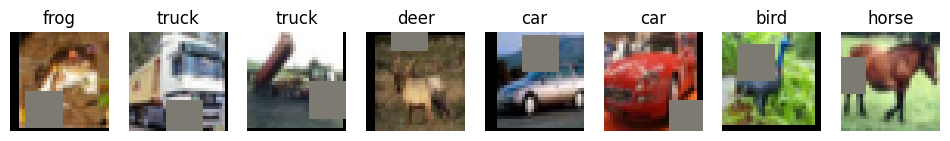

In [4]:
# ---- 4. Augmentation (batched on GPU) + mixup/cutmix ----
def random_crop(x, pad, mode='constant'):
    # pad by `pad` then take a random 32x32 crop per image (vectorized)
    B, C, H, W = x.shape
    xp = F.pad(x, (pad, pad, pad, pad), mode=mode).permute(0, 2, 3, 1)      # B, H+2p, W+2p, C
    oy = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    ox = torch.randint(0, 2 * pad + 1, (B,), device=x.device)
    rows = oy[:, None] + torch.arange(H, device=x.device)                      # B, H
    cols = ox[:, None] + torch.arange(W, device=x.device)                      # B, W
    b = torch.arange(B, device=x.device)[:, None, None]
    out = xp[b, rows[:, :, None], cols[:, None, :]]                            # B, H, W, C
    return out.permute(0, 3, 1, 2).contiguous()

def random_flip(x):
    m = torch.rand(x.shape[0], device=x.device) < 0.5
    return torch.where(m[:, None, None, None], x.flip(3), x)

def cutout(x, size):
    # zero a size x size square (in normalized space, i.e. the mean colour) centred at a random pixel
    B, C, H, W = x.shape
    cy = torch.randint(0, H, (B,), device=x.device)
    cx = torch.randint(0, W, (B,), device=x.device)
    ys, xs = torch.arange(H, device=x.device), torch.arange(W, device=x.device)
    my = (ys[None] >= (cy - size // 2)[:, None]) & (ys[None] < (cy + size // 2)[:, None])
    mx = (xs[None] >= (cx - size // 2)[:, None]) & (xs[None] < (cx + size // 2)[:, None])
    mask = my[:, :, None] & mx[:, None, :]
    return x.masked_fill(mask[:, None], 0.0)

def gpu_augment(x_u8, cfg=None, train=False):
    # uint8 NCHW on GPU -> normalized float, channels_last. Augments only when train=True.
    x = x_u8.float().div_(255)
    if train:
        if cfg['crop_pad'] > 0:
            x = random_crop(x, cfg['crop_pad'], cfg['pad_mode'])
        if cfg['flip']:
            x = random_flip(x)
    x = (x - MEAN) / STD
    if train and cfg['cutout'] > 0:
        x = cutout(x, cfg['cutout'])
    return x.contiguous(memory_format=torch.channels_last)

def mix_batch(x, y, cfg):
    # returns (x, y_a, y_b, lam); loss = lam*CE(y_a) + (1-lam)*CE(y_b)
    use_mixup, use_cutmix = cfg['mixup_alpha'] > 0, cfg['cutmix_alpha'] > 0
    if not (use_mixup or use_cutmix) or np.random.rand() > cfg['mix_prob']:
        return x, y, y, 1.0
    perm = torch.randperm(x.shape[0], device=x.device)
    if use_cutmix and (not use_mixup or np.random.rand() < 0.5):
        lam = np.random.beta(cfg['cutmix_alpha'], cfg['cutmix_alpha'])
        H, W = x.shape[2:]
        ch, cw = int(H * math.sqrt(1 - lam)), int(W * math.sqrt(1 - lam))
        cy, cx = np.random.randint(H), np.random.randint(W)
        y1, y2 = np.clip(cy - ch // 2, 0, H), np.clip(cy + ch // 2, 0, H)
        x1, x2 = np.clip(cx - cw // 2, 0, W), np.clip(cx + cw // 2, 0, W)
        x = x.clone()
        x[:, :, y1:y2, x1:x2] = x[perm, :, y1:y2, x1:x2]
        lam = 1 - (y2 - y1) * (x2 - x1) / (H * W)
    else:
        lam = np.random.beta(cfg['mixup_alpha'], cfg['mixup_alpha'])
        x = lam * x + (1 - lam) * x[perm]
    return x, y, y[perm], float(lam)

# Policy augmentations (AutoAugment etc.) are per-image ops, so they run on CPU workers over the
# in-memory uint8 tensor; crop/flip/cutout/normalize still happen on the GPU afterwards.
POLICIES = {
    'autoaugment':    lambda: v2.AutoAugment(v2.AutoAugmentPolicy.CIFAR10),
    'trivialaugment': lambda: v2.TrivialAugmentWide(),
    'randaugment':    lambda: v2.RandAugment(num_ops=2, magnitude=9),
}

class PolicyDataset(Dataset):
    def __init__(self, x_u8, y, policy):
        self.x, self.y, self.t = x_u8, y, POLICIES[policy]()
    def __len__(self): return len(self.x)
    def __getitem__(self, i): return self.t(self.x[i]), self.y[i]

def gpu_batches(x, y, bs, weights=None):
    # shuffled minibatches straight from GPU memory; weights -> weighted sampling with replacement
    idx = (torch.multinomial(weights, len(x), replacement=True) if weights is not None
           else torch.randperm(len(x), device=x.device))
    for i in range(0, len(x) - len(x) % bs, bs):
        j = idx[i:i + bs]
        yield x[j], y[j]

# quick visual check of the augmentation pipeline
_cfg = dict(crop_pad=4, pad_mode='constant', flip=True, cutout=12)
_xa = gpu_augment(X_all_gpu[:8], _cfg, train=True)
_vis = (_xa * STD + MEAN).clamp(0, 1).permute(0, 2, 3, 1).float().cpu().numpy()
fig, ax = plt.subplots(1, 8, figsize=(12, 2))
for i in range(8):
    ax[i].imshow(_vis[i]); ax[i].set_title(CLASSES[int(Y_all[i])]); ax[i].axis('off')
plt.show()

**Models.** `r<blocks per stage>_<base width>` is a post-activation ResNet whose block computes ReLU(S(x) + F(x)) with F = conv–BN–ReLU–conv–BN. Each new stage halves the resolution (stride-2 first block, 1×1 projection shortcut with BN). `wrnD_K` is a pre-activation Wide ResNet. The table printed below is the **trainable-parameter count of each preset**. Every candidate is under the 5M limit except `wrn28_10`, which is used only as a distillation teacher and is never submitted. `run_experiment` also asserts `params ≤ 5,000,000` for every non-teacher run.

In [5]:
# ---- 5. Models ----
class SE(nn.Module):
    # squeeze-and-excitation channel attention (adds ~2*C^2/r params per block)
    def __init__(self, c, r=16):
        super().__init__()
        h = max(c // r, 8)
        self.fc1, self.fc2 = nn.Conv2d(c, h, 1), nn.Conv2d(h, c, 1)
    def forward(self, x):
        s = F.adaptive_avg_pool2d(x, 1)
        return x * torch.sigmoid(self.fc2(F.relu(self.fc1(s))))

class PadShortcut(nn.Module):
    # parameter-free "option A" shortcut: subsample spatially + zero-pad extra channels
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.stride, self.extra = stride, cout - cin
        assert self.extra >= 0
    def forward(self, x):
        x = x[:, :, ::self.stride, ::self.stride]
        return F.pad(x, (0, 0, 0, 0, 0, self.extra)) if self.extra else x

def make_shortcut(cin, cout, stride, kind, preact):
    if stride == 1 and cin == cout:
        return nn.Identity()
    if kind == 'pad':
        return PadShortcut(cin, cout, stride)
    conv = nn.Conv2d(cin, cout, 1, stride=stride, bias=False)
    return conv if preact else nn.Sequential(conv, nn.BatchNorm2d(cout))

class BasicBlock(nn.Module):
    # post-activation block (original ResNet): conv-BN-ReLU-conv-BN (+SE) + shortcut, ReLU
    def __init__(self, cin, cout, stride, k=3, shortcut='conv', se=False, drop=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, k, stride, k // 2, bias=False); self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, k, 1, k // 2, bias=False);    self.bn2 = nn.BatchNorm2d(cout)
        self.se = SE(cout) if se else nn.Identity()
        self.drop = nn.Dropout(drop) if drop > 0 else nn.Identity()
        self.shortcut = make_shortcut(cin, cout, stride, shortcut, preact=False)
    def forward(self, x):
        out = self.drop(F.relu(self.bn1(self.conv1(x))))
        out = self.se(self.bn2(self.conv2(out)))
        return F.relu(out + self.shortcut(x))

class PreActBlock(nn.Module):
    # pre-activation block (He et al. 2016 / Wide ResNet): BN-ReLU-conv-BN-ReLU-conv (+SE) + shortcut
    def __init__(self, cin, cout, stride, k=3, shortcut='conv', se=False, drop=0.0):
        super().__init__()
        self.bn1 = nn.BatchNorm2d(cin);  self.conv1 = nn.Conv2d(cin, cout, k, stride, k // 2, bias=False)
        self.bn2 = nn.BatchNorm2d(cout); self.conv2 = nn.Conv2d(cout, cout, k, 1, k // 2, bias=False)
        self.se = SE(cout) if se else nn.Identity()
        self.drop = nn.Dropout(drop) if drop > 0 else nn.Identity()
        self.shortcut = make_shortcut(cin, cout, stride, shortcut, preact=True)
        self.needs_proj = not isinstance(self.shortcut, nn.Identity)
    def forward(self, x):
        o = F.relu(self.bn1(x))
        sc = self.shortcut(o) if self.needs_proj else x
        out = self.conv1(o)
        out = self.conv2(self.drop(F.relu(self.bn2(out))))
        return self.se(out) + sc

class ResNet(nn.Module):
    def __init__(self, widths, blocks, block='basic', stem_width=None, kernel=3, stem_kernel=3,
                 shortcut='conv', se=False, block_dropout=0.0, fc_dropout=0.0, num_classes=10):
        super().__init__()
        Block = {'basic': BasicBlock, 'preact': PreActBlock}[block]
        self.preact = block == 'preact'
        stem_width = stem_width or widths[0]
        self.stem = nn.Conv2d(3, stem_width, stem_kernel, 1, stem_kernel // 2, bias=False)
        self.stem_bn = nn.Identity() if self.preact else nn.BatchNorm2d(stem_width)
        layers, cin = [], stem_width
        for s, (w, n) in enumerate(zip(widths, blocks)):
            for b in range(n):
                stride = 2 if (s > 0 and b == 0) else 1
                layers.append(Block(cin, w, stride, kernel, shortcut, se, block_dropout))
                cin = w
        self.layers = nn.Sequential(*layers)
        self.final_bn = nn.BatchNorm2d(cin) if self.preact else nn.Identity()
        self.dropout = nn.Dropout(fc_dropout) if fc_dropout > 0 else nn.Identity()
        self.fc = nn.Linear(cin, num_classes)
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
    def forward(self, x):
        x = self.stem(x)
        x = x if self.preact else F.relu(self.stem_bn(x))
        x = self.layers(x)
        if self.preact:
            x = F.relu(self.final_bn(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)
        return self.fc(self.dropout(x))

# Architecture presets. Names: r<blocks per stage>_<base width>; wrnD_K = Wide ResNet depth D, widen K
ARCH_PRESETS = {
    'baseline_112': dict(widths=[64, 128, 256],      blocks=[1, 1, 2]),      # your original model
    'r222_64':      dict(widths=[64, 128, 256],      blocks=[2, 2, 2]),
    'r223_64':      dict(widths=[64, 128, 256],      blocks=[2, 2, 3]),
    'r343_64':      dict(widths=[64, 128, 256],      blocks=[3, 4, 3]),      # deeper
    'r222_80':      dict(widths=[80, 160, 320],      blocks=[2, 2, 2]),      # wider
    'r2222_40':     dict(widths=[40, 80, 160, 320],  blocks=[2, 2, 2, 2]),   # 4 stages
    'r1111_64':     dict(widths=[64, 128, 256, 512], blocks=[1, 1, 1, 1]),   # half ResNet-18
    'wrn16_4':      dict(widths=[64, 128, 256],      blocks=[2, 2, 2], block='preact', stem_width=16),
    'wrn22_4':      dict(widths=[64, 128, 256],      blocks=[3, 3, 3], block='preact', stem_width=16),
    # teacher for knowledge distillation only (way over budget, never submit this)
    'wrn28_10':     dict(widths=[160, 320, 640],     blocks=[4, 4, 4], block='preact', stem_width=16),
}
ARCH_KEYS = ['widths', 'blocks', 'block', 'stem_width', 'kernel', 'stem_kernel', 'shortcut', 'se',
             'block_dropout', 'fc_dropout']

def arch_kwargs(cfg):
    # preset values, overridden by any explicit (non-None) architecture key in cfg
    kw = dict(ARCH_PRESETS[cfg['arch']]) if cfg.get('arch') else {}
    for k in ARCH_KEYS:
        if cfg.get(k) is not None:
            kw[k] = cfg[k]
    return kw

def build_model(cfg):
    return ResNet(**arch_kwargs(cfg))

def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

PARAM_LIMIT = 5_000_000
print(f"{'preset':14s} {'params':>10s}")
for name in ARCH_PRESETS:
    n = count_params(build_model({'arch': name}))
    print(f"{name:14s} {n:>10,d} {'' if n <= PARAM_LIMIT else '  <-- over 5M'}")

preset             params
baseline_112    2,408,266 
r222_64         2,777,674 
r223_64         3,958,346 
r343_64         4,623,178 
r222_80         4,337,370 
r2222_40        4,368,690 
r1111_64        4,903,242 
wrn16_4         2,748,890 
wrn22_4         4,298,970 
wrn28_10       36,479,194   <-- over 5M


In [6]:
# ---- 6. Training engine ----
DEFAULT_CFG = dict(
    name=None, phase='', notes='', seed=0,
    # architecture (preset name + optional overrides; see ARCH_KEYS)
    arch='r222_64', widths=None, blocks=None, block=None, stem_width=None, kernel=None, stem_kernel=None,
    shortcut=None, se=None, block_dropout=None, fc_dropout=None,
    enforce_budget=True,          # assert <= 5M params (turn off only for a KD teacher)
    # data
    train_on_full=False,          # True = train on all 50k (final model), no validation
    subset=None,                  # use only N training images (smoke tests)
    crop_pad=4, pad_mode='constant', flip=True, cutout=0, policy=None,
    mixup_alpha=0.0, cutmix_alpha=0.0, mix_prob=1.0,
    # class-targeted training (keys = class index, e.g. {3: 1.5, 5: 1.5} for cat/dog)
    oversample=None,              # sample these classes x times as often (with replacement)
    class_weights=None,           # multiply these classes' loss by x
    # optimization
    epochs=30, batch_size=256, lr=0.1, momentum=0.9, nesterov=True, weight_decay=5e-4, wd_on_bn=False,
    label_smoothing=0.1, sched='cosine', warmup_epochs=2, milestones=None,
    amp=True, ema=False, ema_decay=0.999,
    # knowledge distillation: teacher = a run name, or a list of run names (ensemble teacher;
    # their temperature-softened probabilities are averaged)
    teacher=None, kd_alpha=0.5, kd_T=4.0,
    # SAM (sharpness-aware minimization): 0 = off; ~0.05-0.1 typical. Doubles the cost of each step.
    sam_rho=0.0,
    # bookkeeping
    ckpt_every=10, save_weights=True, log=True,
)

def make_cfg(**overrides):
    unknown = set(overrides) - set(DEFAULT_CFG)
    assert not unknown, f'unknown config keys: {unknown}'
    cfg = {**DEFAULT_CFG, **overrides}
    assert cfg['name'], 'every run needs a unique name'
    return cfg

def finished_runs():
    return set(pd.read_csv(RESULTS_CSV)['name']) if os.path.exists(RESULTS_CSV) else set()

def autocast():
    return torch.autocast(device_type='cuda' if device == 'cuda' else 'cpu', dtype=AMP_DTYPE,
                          enabled=(device == 'cuda'))

MULTI_SHIFTS = ((0, 0), (2, 0), (-2, 0), (0, 2), (0, -2))

@torch.no_grad()
def predict_probs(model, x_u8, tta=False, bs=1000, pad=4):
    # softmax probabilities.
    #   tta=False   : single view
    #   tta=True    : average with the horizontally flipped image (2 views)
    #   tta='multi' : 5 small shifts x flip (10 views), shifted with black padding like training crops
    model.eval()
    out = []
    for i in range(0, len(x_u8), bs):
        xb = x_u8[i:i + bs]
        if tta == 'multi':
            x01 = F.pad(xb.float() / 255, (pad, pad, pad, pad))
            views = [((x01[:, :, pad + dy:pad + dy + 32, pad + dx:pad + dx + 32] - MEAN) / STD)
                     .contiguous(memory_format=torch.channels_last) for dy, dx in MULTI_SHIFTS]
        else:
            views = [gpu_augment(xb)]
        if tta:
            views = views + [v.flip(3) for v in views]
        with autocast():
            p = sum(model(v).float().softmax(1) for v in views) / len(views)
        out.append(p)
    return torch.cat(out)

def accuracy(model, x_u8, y, tta=False):
    return (predict_probs(model, x_u8, tta).argmax(1) == y).float().mean().item() * 100

def load_run_model(name):
    # load the final saved weights of a finished run (EMA weights if the run used EMA)
    ck = torch.load(os.path.join(RUNS_DIR, name, 'final.pt'), map_location=device, weights_only=False)
    m = build_model(ck['cfg']).to(device).to(memory_format=torch.channels_last)
    m.load_state_dict(ck['state_dict'])
    return m.eval(), ck['cfg']

def load_teachers(teacher):
    names = [teacher] if isinstance(teacher, str) else list(teacher)
    return [load_run_model(n)[0] for n in names]

def ensemble_val_acc(names, tta=True):
    # sanity check before distilling: is the teacher ensemble actually stronger than one student?
    # Only meaningful for runs trained on the 45k split (they have not seen the val images).
    x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
    acc = lambda p: (p.argmax(1) == y_val).float().mean().item() * 100
    probs = {}
    for n in names:
        m, c = load_run_model(n)
        assert not c['train_on_full'], f'{n} was trained on the val images, its val accuracy is meaningless'
        probs[n] = predict_probs(m, x_val, tta=tta)
        print(f'{n:22s} {acc(probs[n]):.2f}')
        del m
    print(f"{'ENSEMBLE':22s} {acc(sum(probs.values())):.2f}")

def set_bn_momentum(model, momentum=None):
    # momentum=0.0 freezes BN running stats (used for SAM's second forward pass); None restores
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm):
            if momentum is None:
                m.momentum = getattr(m, '_saved_momentum', m.momentum)
            else:
                m._saved_momentum, m.momentum = m.momentum, momentum

def make_scheduler(opt, cfg, steps_per_epoch):
    total = cfg['epochs'] * steps_per_epoch
    if cfg['sched'] == 'onecycle':
        return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=total, pct_start=0.15)
    warm = cfg['warmup_epochs'] * steps_per_epoch
    def f(step):
        if step < warm:
            return (step + 1) / warm
        if cfg['sched'] == 'cosine':
            return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        if cfg['sched'] == 'multistep':
            return 0.1 ** sum(step >= m * steps_per_epoch for m in cfg['milestones'])
        raise ValueError(cfg['sched'])
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def run_experiment(cfg, force=False):
    cfg = make_cfg(**cfg)
    name = cfg['name']
    if cfg['log'] and not force and name in finished_runs():
        print(f'[skip] {name} already in results.csv'); return None
    run_dir = os.path.join(RUNS_DIR, name); os.makedirs(run_dir, exist_ok=True)
    torch.manual_seed(cfg['seed']); np.random.seed(cfg['seed'])

    # ---- data ----
    tr_idx = torch.arange(len(X_all_gpu), device=device) if cfg['train_on_full'] else TRAIN_IDX
    if cfg['subset']:
        tr_idx = tr_idx[:cfg['subset']]
    x_tr, y_tr = X_all_gpu[tr_idx], Y_all_gpu[tr_idx]
    x_val, y_val = (None, None) if cfg['train_on_full'] else (X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX])
    bs = cfg['batch_size']
    sample_w = None
    if cfg['oversample']:
        cw = torch.ones(10)
        for c, f in cfg['oversample'].items():
            cw[int(c)] = float(f)
        sample_w = cw[y_tr.cpu()]
    if cfg['policy']:
        ds = PolicyDataset(x_tr.cpu(), y_tr.cpu(), cfg['policy'])
        sampler = (torch.utils.data.WeightedRandomSampler(sample_w, len(ds), replacement=True)
                   if sample_w is not None else None)
        loader = DataLoader(ds, batch_size=bs, shuffle=sampler is None, sampler=sampler, drop_last=True,
                            num_workers=2, pin_memory=True, persistent_workers=True)
        train_iter, steps = (lambda: loader), len(loader)
    else:
        w_gpu = sample_w.to(device) if sample_w is not None else None
        train_iter, steps = (lambda: gpu_batches(x_tr, y_tr, bs, w_gpu)), len(x_tr) // bs

    # ---- model / optimizer ----
    model = build_model(cfg).to(device).to(memory_format=torch.channels_last)
    n_params = count_params(model)
    if cfg['enforce_budget']:
        assert n_params <= PARAM_LIMIT, f'{name}: {n_params:,} params exceeds the 5M budget'
    decay = [p for p in model.parameters() if p.ndim > 1 or cfg['wd_on_bn']]
    no_decay = [p for p in model.parameters() if not (p.ndim > 1 or cfg['wd_on_bn'])]
    opt = torch.optim.SGD([{'params': decay, 'weight_decay': cfg['weight_decay']},
                           {'params': no_decay, 'weight_decay': 0.0}],
                          lr=cfg['lr'], momentum=cfg['momentum'], nesterov=cfg['nesterov'])
    sched = make_scheduler(opt, cfg, steps)
    scaler = torch.amp.GradScaler('cuda', enabled=(device == 'cuda' and AMP_DTYPE == torch.float16))
    cls_w = None
    if cfg['class_weights']:
        cls_w = torch.ones(10, device=device)
        for c, f in cfg['class_weights'].items():
            cls_w[int(c)] = float(f)
    criterion = nn.CrossEntropyLoss(weight=cls_w, label_smoothing=cfg['label_smoothing'])
    ema = AveragedModel(model, multi_avg_fn=get_ema_multi_avg_fn(cfg['ema_decay']), use_buffers=True) if cfg['ema'] else None
    teachers = load_teachers(cfg['teacher']) if cfg['teacher'] else []

    # ---- resume from checkpoint if a previous session was interrupted ----
    history, start_epoch, ckpt_path = [], 0, os.path.join(run_dir, 'ckpt.pt')
    if cfg['log'] and os.path.exists(ckpt_path) and not force:
        ck = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['opt']); sched.load_state_dict(ck['sched'])
        scaler.load_state_dict(ck['scaler'])
        if ema is not None: ema.load_state_dict(ck['ema'])
        history, start_epoch = ck['history'], ck['epoch'] + 1
        print(f'[resume] {name} from epoch {start_epoch}')

    print(f"[run] {name}: {n_params:,} params, {cfg['epochs']} epochs, {steps} steps/epoch")
    bar = tqdm(range(start_epoch, cfg['epochs']), desc=name, initial=start_epoch, total=cfg['epochs'])
    for epoch in bar:
        model.train()
        if device == 'cuda': torch.cuda.synchronize()
        t0 = time.time()
        loss_sum = torch.zeros((), device=device); correct = torch.zeros((), device=device); seen = 0
        for xb, yb in train_iter():
            xb, yb = xb.to(device, non_blocking=True), yb.to(device, non_blocking=True)
            x = gpu_augment(xb, cfg, train=True)
            x, ya, yb2, lam = mix_batch(x, yb, cfg)
            T = cfg['kd_T']
            t_probs = None
            if teachers:   # averaged temperature-softened teacher probabilities, computed once per batch
                with torch.no_grad(), autocast():
                    t_probs = torch.stack([F.softmax(t(x).float() / T, 1) for t in teachers]).mean(0)

            def compute_loss(out):
                loss = lam * criterion(out, ya) + (1 - lam) * criterion(out, yb2) if lam < 1 else criterion(out, ya)
                if t_probs is not None:
                    kd = F.kl_div(F.log_softmax(out.float() / T, 1), t_probs, reduction='batchmean') * T * T
                    loss = (1 - cfg['kd_alpha']) * loss + cfg['kd_alpha'] * kd
                return loss

            opt.zero_grad(set_to_none=True)
            with autocast():
                out = model(x)
                loss = compute_loss(out)
            scaler.scale(loss).backward()

            if cfg['sam_rho'] > 0:
                # SAM: move to w + e (e = rho * g/||g||, the locally worst-case direction), take the
                # gradient there, return to w, and step with that gradient.
                params = [p for p in model.parameters() if p.grad is not None]
                inv_scale = 1.0 / scaler.get_scale()          # grads are loss-scaled under fp16 AMP
                gnorm = torch.norm(torch.stack([p.grad.norm() * inv_scale for p in params]))
                if torch.isfinite(gnorm):                     # on fp16 overflow skip SAM; scaler skips the step anyway
                    k = cfg['sam_rho'] / (gnorm + 1e-12)
                    with torch.no_grad():
                        eps = [p.grad * inv_scale * k for p in params]
                        for p, e in zip(params, eps):
                            p.add_(e)
                    opt.zero_grad(set_to_none=True)
                    set_bn_momentum(model, 0.0)               # don't update BN running stats twice
                    with autocast():
                        loss2 = compute_loss(model(x))
                    scaler.scale(loss2).backward()
                    set_bn_momentum(model, None)
                    with torch.no_grad():
                        for p, e in zip(params, eps):
                            p.sub_(e)

            scaler.step(opt); scaler.update(); sched.step()
            if ema is not None:
                ema.update_parameters(model)
            loss_sum += loss.detach() * len(yb); correct += (out.argmax(1) == yb).sum(); seen += len(yb)
        if device == 'cuda': torch.cuda.synchronize()
        rec = dict(epoch=epoch + 1, lr=opt.param_groups[0]['lr'], epoch_sec=time.time() - t0,
                   train_loss=loss_sum.item() / seen, train_acc=correct.item() / seen * 100)
        if x_val is not None:
            rec['val_acc'] = accuracy(model, x_val, y_val)
            if ema is not None:
                rec['ema_val_acc'] = accuracy(ema, x_val, y_val)
        history.append(rec)
        bar.set_postfix({k: round(v, 2) for k, v in rec.items() if k in ('train_loss', 'train_acc', 'val_acc', 'ema_val_acc')})
        if cfg.get('snapshot_every') and (epoch + 1) % cfg['snapshot_every'] == 0:          # NEW
            save_snapshot(cfg, epoch + 1, ema.module if ema is not None else model, run_dir)  # NEW
        if cfg['log'] and cfg['ckpt_every'] and (epoch + 1) % cfg['ckpt_every'] == 0 and epoch + 1 < cfg['epochs']:
            torch.save(dict(model=model.state_dict(), opt=opt.state_dict(), sched=sched.state_dict(),
                            scaler=scaler.state_dict(), ema=ema.state_dict() if ema is not None else None,
                            history=history, epoch=epoch), ckpt_path)

    # ---- final metrics (final epoch, no checkpoint picking -> unbiased estimate) ----
    final_model = ema.module if ema is not None else model
    row = dict(name=name, phase=cfg['phase'], notes=cfg['notes'], arch=cfg['arch'], params=n_params,
               epochs=cfg['epochs'], gpu=GPU_NAME,
               sec_per_epoch=round(float(np.mean([h['epoch_sec'] for h in history[-5:]])), 2),
               train_acc=round(history[-1]['train_acc'], 2))
    if x_val is not None:
        row.update(val_acc=round(accuracy(model, x_val, y_val), 2),
                   val_acc_tta=round(accuracy(model, x_val, y_val, tta=True), 2),
                   best_val_acc=round(max(h['val_acc'] for h in history), 2),
                   best_epoch=int(np.argmax([h['val_acc'] for h in history]) + 1))
        if ema is not None:
            row.update(ema_val_acc=round(accuracy(ema, x_val, y_val), 2),
                       ema_val_acc_tta=round(accuracy(ema, x_val, y_val, tta=True), 2))
        # multi-crop TTA of the model that gets saved (EMA weights if EMA is on)
        row['final_val_acc_mtta'] = round(accuracy(final_model, x_val, y_val, tta='multi'), 2)
    row.update(timestamp=datetime.datetime.now().isoformat(timespec='seconds'), cfg_json=json.dumps(cfg))
    print({k: v for k, v in row.items() if k != 'cfg_json'})

    if cfg['log']:
        with open(os.path.join(run_dir, 'history.json'), 'w') as f:
            json.dump(dict(cfg=cfg, history=history, result={k: v for k, v in row.items() if k != 'cfg_json'}), f)
        if cfg['save_weights']:
            torch.save(dict(cfg=cfg, state_dict=final_model.state_dict()), os.path.join(run_dir, 'final.pt'))
        # read-concat-rewrite (not append) so runs with different metric columns stay aligned
        df = pd.read_csv(RESULTS_CSV) if os.path.exists(RESULTS_CSV) else pd.DataFrame()
        pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
        if os.path.exists(ckpt_path):
            os.remove(ckpt_path)
    return final_model

def run_grid(cfgs):
    names = [c['name'] for c in cfgs]
    assert len(names) == len(set(names)), 'duplicate run names in grid'
    for c in cfgs:
        run_experiment(c)
        if device == 'cuda': torch.cuda.empty_cache()

# ---- result viewing helpers ----
SHOW_COLS = ['name', 'arch', 'params', 'epochs', 'val_acc', 'val_acc_tta', 'ema_val_acc', 'ema_val_acc_tta',
             'final_val_acc_mtta', 'best_val_acc', 'train_acc', 'sec_per_epoch', 'notes']

def show_results(phase=None):
    if not os.path.exists(RESULTS_CSV):
        print('no results yet'); return None
    df = pd.read_csv(RESULTS_CSV)
    if phase is not None:
        df = df[df['phase'] == phase]
    cols = [c for c in SHOW_COLS if c in df.columns and df[c].notna().any()]
    return df[cols].sort_values('val_acc', ascending=False).reset_index(drop=True)

def plot_curves(names, key='val_acc'):
    fig, ax = plt.subplots(1, 2, figsize=(13, 4))
    for n in names:
        p = os.path.join(RUNS_DIR, n, 'history.json')
        if not os.path.exists(p): continue
        h = json.load(open(p))['history']
        e = [r['epoch'] for r in h]
        if key in h[0]: ax[0].plot(e, [r[key] for r in h], label=n)
        ax[1].plot(e, [r['train_loss'] for r in h], label=n)
    ax[0].set(xlabel='epoch', ylabel=key, title='validation accuracy'); ax[0].grid(alpha=.3)
    ax[1].set(xlabel='epoch', ylabel='train loss', title='training loss'); ax[1].grid(alpha=.3)
    ax[0].legend(fontsize=8); plt.show()

**6b: robustness additions** (used in Phase 7): photometric jitter, random grayscale, blur/sharpen degradation, and an optional per-image input standardization. The figure shows the original images (top) and the strongest version of these augmentations (bottom).

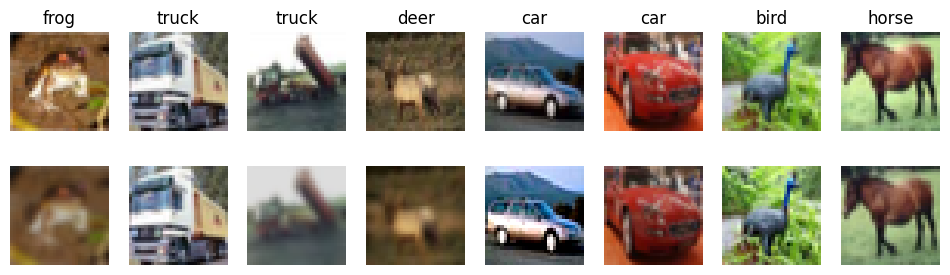

In [7]:
# ---- 6b. Robustness additions: photometric / degradation augmentation + per-image input normalization ----
# Run right after cell 6, every session. Every new option defaults to OFF, so earlier runs reproduce exactly
# and all existing checkpoints still load.
import io

DEFAULT_CFG.update(
    photo_p=0.0,        # per-image probability of a random brightness/contrast/saturation change
    brightness=0.2,     # multiplicative brightness factor drawn from [1-b, 1+b]
    contrast=0.2,       # contrast factor drawn from [1-c, 1+c] (blend with the image's mean grey level)
    saturation=0.2,     # saturation factor drawn from [1-s, 1+s] (blend with the greyscale image)
    gray_p=0.0,         # per-image probability of converting to greyscale
    degrade_p=0.0,      # per-image probability of a resolution change: half blur (down/up resample), half sharpen
    input_norm=None,    # None = dataset mean/std only; 'image' = the model also standardizes each image by its own mean/std
)

def _gray(x):
    # B,3,H,W in [0,1] -> B,1,H,W luminance
    return 0.299 * x[:, 0:1] + 0.587 * x[:, 1:2] + 0.114 * x[:, 2:3]

def _rand_factor(B, amt, dev):
    return 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * amt

def photometric(x, cfg):
    # random brightness, contrast and saturation (each with its own per-image factor) for a photo_p fraction of images
    B, dev = x.shape[0], x.device
    y = x * _rand_factor(B, cfg['brightness'], dev)
    m = _gray(y).mean(dim=(1, 2, 3), keepdim=True)
    y = (y - m) * _rand_factor(B, cfg['contrast'], dev) + m
    g = _gray(y)
    y = ((y - g) * _rand_factor(B, cfg['saturation'], dev) + g).clamp(0, 1)
    sel = torch.rand(B, 1, 1, 1, device=dev) < cfg['photo_p']
    return torch.where(sel, y, x)

def random_gray(x, p):
    sel = torch.rand(x.shape[0], 1, 1, 1, device=x.device) < p
    return torch.where(sel, _gray(x).expand_as(x), x)

def blur_resample(x, scale):
    # downsample then upsample back: loses fine detail, like a lower-resolution source photo
    H, W = x.shape[2:]
    s = max(8, int(round(H * scale)))
    small = F.interpolate(x, size=(s, s), mode='bilinear', align_corners=False, antialias=True)
    return F.interpolate(small, size=(H, W), mode='bilinear', align_corners=False)

def sharpen(x, amount):
    # unsharp mask: x + amount * (x - blur(x))
    k = torch.tensor([1., 2., 1.], device=x.device, dtype=x.dtype)
    k = ((k[:, None] * k[None, :]) / 16).expand(x.shape[1], 1, 3, 3).contiguous()
    blur = F.conv2d(F.pad(x, (1, 1, 1, 1), mode='replicate'), k, groups=x.shape[1])
    return (x + amount * (x - blur)).clamp(0, 1)

def degrade(x, p):
    # a p/2 fraction of images is blurred (random down/up resample), another p/2 fraction is sharpened
    r = torch.rand(x.shape[0], device=x.device)[:, None, None, None]
    out = torch.where(r < p / 2, blur_resample(x, float(np.random.uniform(0.5, 0.85))), x)
    return torch.where((r >= p / 2) & (r < p), sharpen(x, float(np.random.uniform(0.3, 1.0))), out)

def gpu_augment(x_u8, cfg=None, train=False):
    # (replaces the cell-4 version) uint8 NCHW on GPU -> normalized float, channels_last.
    # Photometric/degradation ops run in [0,1] space before crop/flip; all are skipped when their option is 0.
    x = x_u8.float().div_(255)
    if train:
        if cfg.get('photo_p', 0) > 0:
            x = photometric(x, cfg)
        if cfg.get('gray_p', 0) > 0:
            x = random_gray(x, cfg['gray_p'])
        if cfg.get('degrade_p', 0) > 0:
            x = degrade(x, cfg['degrade_p'])
        if cfg['crop_pad'] > 0:
            x = random_crop(x, cfg['crop_pad'], cfg['pad_mode'])
        if cfg['flip']:
            x = random_flip(x)
    x = (x - MEAN) / STD
    if train and cfg['cutout'] > 0:
        x = cutout(x, cfg['cutout'])
    return x.contiguous(memory_format=torch.channels_last)

class ResNetIN(ResNet):
    # Same network, but each input image is also standardized by its own mean/std (over all pixels and
    # channels). This removes global brightness/contrast differences while keeping colour. It has no
    # parameters or buffers, so the parameter count and state_dict are identical to plain ResNet, and it
    # runs inside the model, so every predict/TTA path gets it automatically.
    def forward(self, x):
        xf = x.float()
        m = xf.mean(dim=(1, 2, 3), keepdim=True)
        s = xf.std(dim=(1, 2, 3), keepdim=True).clamp_min(0.2)   # floor avoids blowing up near-flat images
        x = ((xf - m) / s).to(x.dtype).contiguous(memory_format=torch.channels_last)
        return super().forward(x)

def build_model(cfg):
    # (replaces the cell-5 version) old configs have no 'input_norm' key -> plain ResNet, as before
    cls = ResNetIN if cfg.get('input_norm') == 'image' else ResNet
    return cls(**arch_kwargs(cfg))

# quick visual check: top row original, bottom row with strong photometric + degradation augmentation
_cfg = dict(crop_pad=0, pad_mode='constant', flip=False, cutout=0, photo_p=1.0, brightness=0.2,
            contrast=0.2, saturation=0.2, gray_p=0.1, degrade_p=0.5)
_x8 = X_all_gpu[:8]
_xa = (gpu_augment(_x8, _cfg, train=True) * STD + MEAN).clamp(0, 1)
fig, ax = plt.subplots(2, 8, figsize=(12, 3.2))
for i in range(8):
    ax[0, i].imshow(_x8[i].permute(1, 2, 0).cpu()); ax[0, i].set_title(CLASSES[int(Y_all[i])]); ax[0, i].axis('off')
    ax[1, i].imshow(_xa[i].permute(1, 2, 0).float().cpu()); ax[1, i].axis('off')
plt.show()

**6c: long-run tools** (used in Phase 8): a cosine schedule with warm restarts, and a snapshot every N epochs (weights, validation accuracy and a `submission.csv`).

In [8]:
# ---- 6c. Long runs: cosine-with-restarts schedule + a snapshot and submission.csv every N epochs ----
DEFAULT_CFG.update(
    cycle_epochs=100,     # for sched='cosine_restart': LR decays to ~0 every cycle_epochs, then restarts
    cycle_decay=1.0,      # peak LR multiplier per cycle (e.g. 0.8 = each restart is gentler); 1.0 = same peak
    snapshot_every=0,     # >0: every N epochs save weights + val accuracy (45k runs) + submission csv
)
SNAP_TTA = 'multi'        # same TTA as your current submission

def make_scheduler(opt, cfg, steps_per_epoch):
    # (replaces the cell-6 version; adds 'cosine_restart', everything else unchanged)
    total = cfg['epochs'] * steps_per_epoch
    if cfg['sched'] == 'onecycle':
        return torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=cfg['lr'], total_steps=total, pct_start=0.15)
    warm = cfg['warmup_epochs'] * steps_per_epoch
    def f(step):
        if step < warm:
            return (step + 1) / warm
        if cfg['sched'] == 'cosine':
            return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))
        if cfg['sched'] == 'cosine_restart':
            cyc = cfg['cycle_epochs'] * steps_per_epoch      # cycles aligned to epoch 0, so they end at
            k, t = divmod(step, cyc)                         # exactly epochs 100, 200, ...
            return cfg['cycle_decay'] ** k * 0.5 * (1 + math.cos(math.pi * t / cyc))
        if cfg['sched'] == 'multistep':
            return 0.1 ** sum(step >= m * steps_per_epoch for m in cfg['milestones'])
        raise ValueError(cfg['sched'])
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def save_snapshot(cfg, ep, model, run_dir):
    # weights + (45k runs only) validation accuracy + submission csv for the model at this epoch
    tag = f'e{ep:03d}'
    torch.save(dict(cfg=cfg, state_dict=model.state_dict(), epoch=ep), os.path.join(run_dir, f'snap_{tag}.pt'))
    row = dict(name=cfg['name'], epoch=ep)
    if not cfg['train_on_full']:
        row['val_acc_mtta'] = round(accuracy(model, X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX], tta=SNAP_TTA), 2)
    preds = predict_probs(model, X_test_gpu, tta=SNAP_TTA).argmax(1).cpu().numpy().astype(int)
    sub = pd.DataFrame({'id': TEST_IDS, 'label': preds})
    assert len(sub) == len(TEST_IDS) and sub['id'].is_unique and sub['label'].between(0, 9).all()
    if SAMPLE_SUB is not None:
        assert set(sub['id']) == set(SAMPLE_SUB['id']), 'ids differ from sample_submission'
    path = os.path.join(run_dir, f'submission_{tag}.csv')
    sub.to_csv(path, index=False)
    row['pred_counts'] = np.bincount(preds, minlength=10).tolist()
    snap_csv = os.path.join(run_dir, 'snapshots.csv')
    df = pd.read_csv(snap_csv) if os.path.exists(snap_csv) else pd.DataFrame()
    df = df[df['epoch'] != ep] if len(df) else df                 # re-snapshot after a resume replaces the row
    pd.concat([df, pd.DataFrame([row])], ignore_index=True).to_csv(snap_csv, index=False)
    print(f'\n[snapshot] {cfg["name"]} epoch {ep}: {row.get("val_acc_mtta", "(no val)")} -> {path}')

### Smoke test
One epoch on a small subset, not logged. It checks that the data, augmentation, Mixup, EMA and AutoAugment code paths run end to end before any long run. The accuracies printed here (~15–20%) are meaningless after one epoch.

In [9]:
# ---- Smoke test (~1 min): 1 epoch on 5k images, not logged. Also exercises cutout, mixup, and EMA paths. ----
_ = run_experiment(make_cfg(name='smoke', subset=5000, epochs=1, warmup_epochs=0, cutout=16,
                            mixup_alpha=0.2, ema=True, log=False))
_ = run_experiment(make_cfg(name='smoke_policy', subset=2048, epochs=1, warmup_epochs=0,
                            policy='trivialaugment', log=False))

[run] smoke: 2,777,674 params, 1 epochs, 19 steps/epoch


smoke:   0%|          | 0/1 [00:00<?, ?it/s]

{'name': 'smoke', 'phase': '', 'notes': '', 'arch': 'r222_64', 'params': 2777674, 'epochs': 1, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 7.67, 'train_acc': 13.45, 'val_acc': 18.36, 'val_acc_tta': 18.32, 'best_val_acc': 18.36, 'best_epoch': 1, 'ema_val_acc': 13.84, 'ema_val_acc_tta': 13.98, 'final_val_acc_mtta': 13.9, 'timestamp': '2026-11-11T22:15:26'}
[run] smoke_policy: 2,777,674 params, 1 epochs, 8 steps/epoch


smoke_policy:   0%|          | 0/1 [00:00<?, ?it/s]

{'name': 'smoke_policy', 'phase': '', 'notes': '', 'arch': 'r222_64', 'params': 2777674, 'epochs': 1, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 0.51, 'train_acc': 13.23, 'val_acc': 16.86, 'val_acc_tta': 16.74, 'best_val_acc': 16.86, 'best_epoch': 1, 'final_val_acc_mtta': 16.14, 'timestamp': '2026-11-11T22:15:29'}


## Phase 0: Augmentation and training-recipe ablation (30 epochs)

Before searching architectures, we need a training recipe we trust, and we want to know how much each part of it is worth. We start from our original 2.4M-parameter model (`baseline_112`) and add one change at a time:
- **A**: the original setup: no augmentation, batch 64, step learning-rate schedule, no label smoothing;
- **B**: A + random crop (4-pixel padding) and horizontal flip;
- **C**: B + batch 256, Nesterov momentum, warmup + cosine schedule, label smoothing 0.1, no weight decay on BN parameters.

[skip] p0_A_original already in results.csv
[skip] p0_B_aug already in results.csv
[skip] p0_C_aug_recipe already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,best_val_acc,train_acc,sec_per_epoch,notes
0,p0_C_aug_recipe,baseline_112,2408266,30,92.12,92.74,92.12,99.56,6.29,"B + bs256, nesterov, cosine+warmup, LS 0.1, no..."
1,p0_B_aug,baseline_112,2408266,30,91.80,92.30,91.98,97.40,7.24,A + crop/flip
2,p0_A_original,baseline_112,2408266,30,87.76,89.88,87.88,100.00,7.05,"original: no aug, bs64, multistep, no LS"


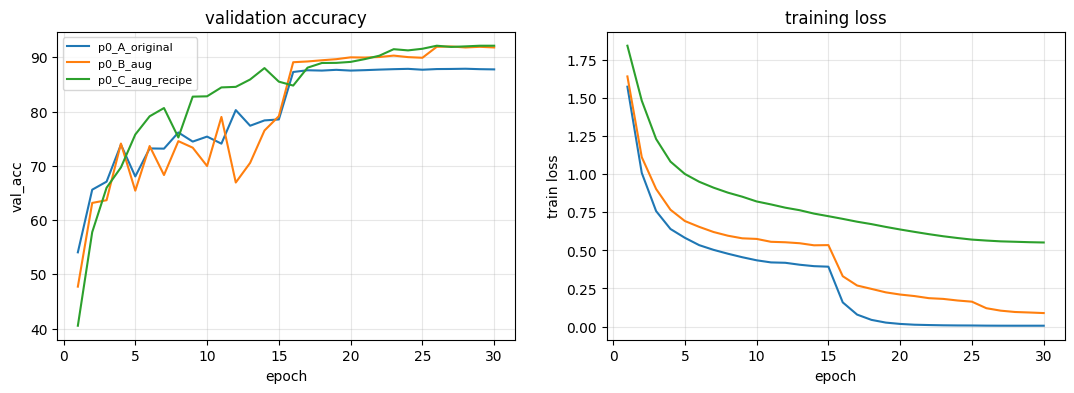

In [10]:
P0 = [
    make_cfg(name='p0_A_original', phase='p0', arch='baseline_112', notes='original: no aug, bs64, multistep, no LS',
             crop_pad=0, flip=False, batch_size=64, lr=0.1, nesterov=False, label_smoothing=0.0,
             sched='multistep', milestones=[15, 25], warmup_epochs=0, wd_on_bn=True),
    make_cfg(name='p0_B_aug', phase='p0', arch='baseline_112', notes='A + crop/flip',
             batch_size=64, nesterov=False, label_smoothing=0.0, sched='multistep', milestones=[15, 25],
             warmup_epochs=0, wd_on_bn=True),
    make_cfg(name='p0_C_aug_recipe', phase='p0', arch='baseline_112',
             notes='B + bs256, nesterov, cosine+warmup, LS 0.1, no wd on BN'),
]
run_grid(P0)
display(show_results('p0'))
plot_curves([c['name'] for c in P0])

**Results**

| Run | Val acc (%) | Train acc (%) |
|---|---|---|
| A: original | 87.76 | 100.00 |
| B: + crop/flip | 91.80 | 97.40 |
| C: + recipe | **92.12** | 99.56 |

- Run A reaches 100% training accuracy but only 87.8% validation accuracy: it memorizes the training set (overfitting).
- Crop/flip is the largest single gain (+4.0 points). Training accuracy drops below 100%, so the network can no longer simply memorize.
- The recipe changes add another +0.3 points and train faster (6.3 vs. 7.2 s/epoch).

**Decision:** recipe C is the base for every later phase.

## Phase 1: Architecture search (fixed recipe, 30 epochs)

With the recipe fixed, we need to figure out how to distribute 5M parameters. We compare eight shapes under the limit that vary three things:
- **width** (channels per stage): `r222_64` vs. `r222_80`;
- **depth** (blocks per stage): `r222_64` vs. `r223_64` vs. `r343_64`;
- **number of stages** (how often the image is downsampled): the 3-stage models vs. `r2222_40` and `r1111_64` (4 stages, like ResNet-18);
- plus two pre-activation Wide-ResNet variants (`wrn16_4`, `wrn22_4`).

30 epochs is enough to rank the shapes cheaply, since all of them fit the training set almost perfectly in that time.

[skip] p1_r222_64 already in results.csv
[skip] p1_r223_64 already in results.csv
[skip] p1_r343_64 already in results.csv
[skip] p1_r222_80 already in results.csv
[skip] p1_r2222_40 already in results.csv
[skip] p1_r1111_64 already in results.csv
[skip] p1_wrn16_4 already in results.csv
[skip] p1_wrn22_4 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,best_val_acc,train_acc,sec_per_epoch
0,p1_r222_80,r222_80,4337370,30,93.32,93.86,93.32,99.79,18.57
1,p1_r343_64,r343_64,4623178,30,93.18,94.00,93.30,99.65,16.40
2,p1_r223_64,r223_64,3958346,30,93.14,93.76,93.30,99.74,11.42
3,p1_wrn22_4,wrn22_4,4298970,30,93.06,93.48,93.12,99.72,14.20
4,p1_wrn16_4,wrn16_4,2748890,30,93.04,93.36,93.08,99.64,9.45
5,p1_r222_64,r222_64,2777674,30,92.74,93.34,92.76,99.73,10.17
6,p1_r2222_40,r2222_40,4368690,30,92.26,93.04,92.26,98.98,9.32
7,p1_r1111_64,r1111_64,4903242,30,92.22,92.86,92.30,98.80,6.44


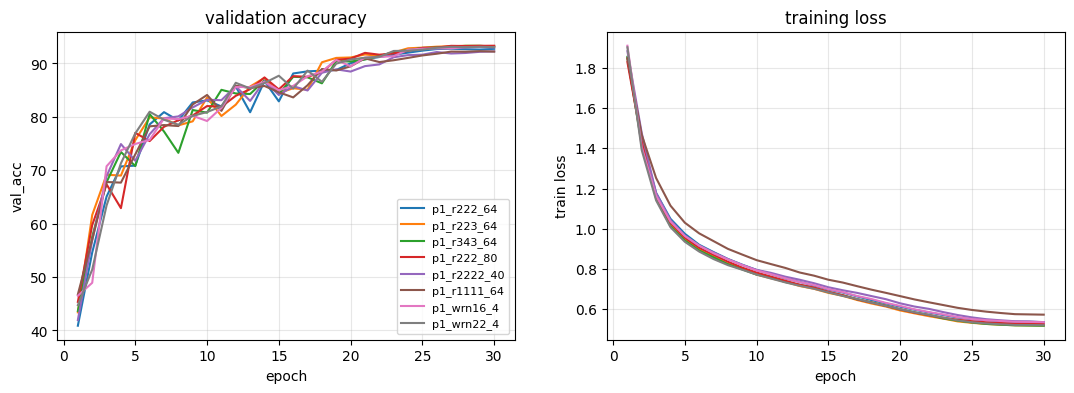

In [11]:
P1 = [make_cfg(name=f'p1_{a}', phase='p1', arch=a)
      for a in ['r222_64', 'r223_64', 'r343_64', 'r222_80', 'r2222_40', 'r1111_64', 'wrn16_4', 'wrn22_4']]
run_grid(P1)
display(show_results('p1'))
plot_curves([c['name'] for c in P1])

**Results**
- **`r222_80` (wide, 3 stages) is best at 93.32%**, just ahead of the deeper `r343_64` (93.18%). That gap is within noise, so both are kept: `r222_80` as the student and `r343_64` as a teacher.
- **Every 4-stage network is worse** (92.26%, 92.22%), even though `r1111_64` has the most parameters (4.9M). A fourth stage works on 4×4 feature maps and takes most of the budget: one 3×3 convolution at 512 channels is 2.4M parameters, which leaves the early layers only 40 channels (`r2222_40`).
- Within three stages, more parameters help whether they go into width or depth (`r222_64`, 2.78M: 92.74% → `r223_64`, 3.96M: 93.14% → `r222_80`, 4.34M: 93.32%). At the top of the budget, width edges out depth (`r222_80` vs. `r343_64`).
- All models reach 98.8–99.8% training accuracy, so the differences come from generalization, not from fitting the training set.

**Decision:** `BEST_ARCH = 'r222_80'`.

### Phase 1b: Block-level variants (30 epochs)
Having picked the shape, we check whether a different block design helps at almost the same parameter count: pre-activation blocks, squeeze-and-excitation channel attention (+36k params), parameter-free shortcuts, and dropout before the classifier. The table also contains the same variants on `r343_64`, from the earlier pass.

In [12]:
# Phase 1b: block design ablations on the best Phase-1 architecture
BEST_ARCH = 'r222_80'   # <-- set from the Phase 1 table

P1B = [
    make_cfg(name=f'p1b_{BEST_ARCH}_preact',   phase='p1b', arch=BEST_ARCH, block='preact', notes='pre-activation blocks'),
    make_cfg(name=f'p1b_{BEST_ARCH}_se',       phase='p1b', arch=BEST_ARCH, se=True, notes='squeeze-excitation'),
    make_cfg(name=f'p1b_{BEST_ARCH}_padskip',  phase='p1b', arch=BEST_ARCH, shortcut='pad', notes='parameter-free shortcut'),
    make_cfg(name=f'p1b_{BEST_ARCH}_fcdrop',   phase='p1b', arch=BEST_ARCH, fc_dropout=0.2, notes='dropout before FC'),
]
# kernel size: 5x5 convs cost ~2.8x the params, so test on a smaller net, e.g.
# make_cfg(name='p1b_r111_k5', phase='p1b', widths=[64,128,256], blocks=[1,1,1], kernel=5, arch=None)
for c in P1B:  # print param counts first; anything over 5M will assert when it runs
    print(c['name'], f"{count_params(build_model(c)):,}")
run_grid(P1B)
display(show_results('p1b'))

p1b_r222_80_preact 4,336,410
p1b_r222_80_se 4,373,126
p1b_r222_80_padskip 4,272,410
p1b_r222_80_fcdrop 4,337,370
[skip] p1b_r222_80_preact already in results.csv
[skip] p1b_r222_80_se already in results.csv
[skip] p1b_r222_80_padskip already in results.csv
[skip] p1b_r222_80_fcdrop already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,best_val_acc,train_acc,sec_per_epoch,notes
0,p1b_r343_64_padskip,r343_64,4581450,30,93.24,93.64,93.32,99.62,16.76,parameter-free shortcut
1,p1b_r222_80_preact,r222_80,4336410,30,93.24,93.84,93.32,99.78,16.32,pre-activation blocks
2,p1b_r222_80_fcdrop,r222_80,4337370,30,93.18,93.68,93.22,99.77,16.54,dropout before FC
3,p1b_r343_64_preact,r343_64,4622410,30,93.10,93.70,93.10,99.72,16.24,pre-activation blocks
4,p1b_r222_80_padskip,r222_80,4272410,30,93.02,93.72,93.02,99.76,16.72,parameter-free shortcut
5,p1b_r222_80_se,r222_80,4373126,30,93.00,93.22,93.00,99.55,18.81,squeeze-excitation
6,p1b_r343_64_fcdrop,r343_64,4623178,30,92.86,93.52,92.90,99.52,16.43,dropout before FC
7,p1b_r343_64_se,r343_64,4660594,30,92.84,93.74,92.92,99.62,19.43,squeeze-excitation


**Results:** on `r222_80`, every variant scores **93.00–93.24% against 93.32% for the plain block**, and the same holds on `r343_64`. All of these differences are within seed noise. Pre-activation mainly helps much deeper networks than our 14 layers, and squeeze-and-excitation adds 36k parameters for no gain.

**Decision:** keep the plain basic block with 1×1 projection shortcuts (`BEST_ARCH_CFG = dict(arch='r222_80')`).

## Phase 2: Augmentation and regularization (60 epochs)

Phase 1 models fit the training set almost perfectly, so the next lever is regularization. Strong regularization usually hurts at short training budgets and helps once training is longer, so this phase uses 60 epochs. Every row is compared with `p2_base` (crop + flip only):
- **policy augmentation:** AutoAugment (CIFAR-10 policy), TrivialAugment;
- **occlusion:** Cutout 16×16;
- **label mixing:** Mixup (α = 0.2), CutMix (α = 1, p = 0.5);
- **weight averaging:** EMA of the weights (decay 0.999);
- removing label smoothing;
- the combination AutoAugment + Cutout + EMA.

Policy augmentations run on CPU workers, so their epochs are slower. Rows without the `_r222_80` suffix are `r343_64`, from the earlier pass.

[skip] p2_base_r222_80 already in results.csv
[skip] p2_cutout16_r222_80 already in results.csv
[skip] p2_autoaug_r222_80 already in results.csv
[skip] p2_trivialaug_r222_80 already in results.csv
[skip] p2_mixup_r222_80 already in results.csv
[skip] p2_cutmix_r222_80 already in results.csv
[skip] p2_ema_r222_80 already in results.csv
[skip] p2_ls0_r222_80 already in results.csv
[skip] p2_combo_r222_80 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,best_val_acc,train_acc,sec_per_epoch,notes
0,p2_autoaug_r222_80,r222_80,4337370,60,95.48,95.68,NaN,NaN,95.56,96.59,20.20,NaN
1,p2_combo_r222_80,r222_80,4337370,60,95.46,95.68,95.60,95.64,95.64,91.82,20.52,NaN
2,p2_cutout16_r222_80,r222_80,4337370,60,95.30,95.70,NaN,NaN,95.42,98.02,18.66,NaN
3,p2_combo,r343_64,4623178,60,95.28,95.64,95.28,95.74,95.34,91.90,18.23,NaN
4,p2_cutout16,r343_64,4623178,60,95.26,95.62,NaN,NaN,95.32,97.59,16.39,NaN
5,p2_cutmix_r222_80,r222_80,4337370,60,94.96,95.30,NaN,NaN,94.96,88.23,18.74,NaN
6,p2_trivialaug,r343_64,4623178,60,94.96,95.48,NaN,NaN,95.00,91.38,16.55,NaN
7,p2_autoaug,r343_64,4623178,60,94.90,95.74,NaN,NaN,94.96,96.41,16.67,NaN
8,p2_cutmix,r343_64,4623178,60,94.88,95.20,NaN,NaN,94.88,88.14,16.46,NaN
9,p2_trivialaug_r222_80,r222_80,4337370,60,94.82,95.16,NaN,NaN,94.88,91.49,19.53,NaN


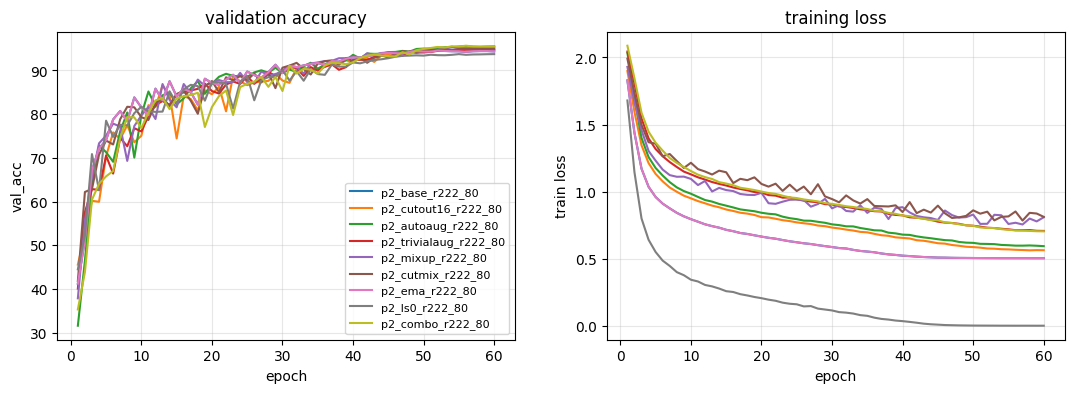

In [13]:
BEST_ARCH_CFG = dict(arch=BEST_ARCH)          # <-- add any winning Phase-1b overrides, e.g. dict(arch=BEST_ARCH, se=True)
E2 = 60
P2 = [
    make_cfg(name='p2_base',         phase='p2', epochs=E2, **BEST_ARCH_CFG, notes='crop+flip only'),
    make_cfg(name='p2_cutout16',     phase='p2', epochs=E2, **BEST_ARCH_CFG, cutout=16),
    make_cfg(name='p2_autoaug',      phase='p2', epochs=E2, **BEST_ARCH_CFG, policy='autoaugment'),
    make_cfg(name='p2_trivialaug',   phase='p2', epochs=E2, **BEST_ARCH_CFG, policy='trivialaugment'),
    make_cfg(name='p2_mixup',        phase='p2', epochs=E2, **BEST_ARCH_CFG, mixup_alpha=0.2),
    make_cfg(name='p2_cutmix',       phase='p2', epochs=E2, **BEST_ARCH_CFG, cutmix_alpha=1.0, mix_prob=0.5),
    make_cfg(name='p2_ema',          phase='p2', epochs=E2, **BEST_ARCH_CFG, ema=True),
    make_cfg(name='p2_ls0',          phase='p2', epochs=E2, **BEST_ARCH_CFG, label_smoothing=0.0, notes='label smoothing off'),
    make_cfg(name='p2_combo',        phase='p2', epochs=E2, **BEST_ARCH_CFG, policy='autoaugment', cutout=16, ema=True),
]
for c in P2: c['name'] += f'_{BEST_ARCH}'
run_grid(P2)
display(show_results('p2'))
plot_curves([c['name'] for c in P2])

**Results (`r222_80`, 60 epochs, no TTA)**

| Method | Val acc (%) | Δ vs. crop/flip | Train acc (%) |
|---|---|---|---|
| Crop + flip only | 94.34 | — | 100.00 |
| + AutoAugment | **95.48** | +1.14 | 96.59 |
| + AutoAugment + Cutout + EMA | 95.46 | +1.12 | 91.82 |
| + Cutout 16×16 | 95.30 | +0.96 | 98.02 |
| + CutMix | 94.96 | +0.62 | 88.23 |
| + TrivialAugment | 94.82 | +0.48 | 91.49 |
| + Mixup | 94.60 | +0.26 | 53.52* |
| + EMA alone | 94.34 | 0.00 | 100.00 |
| Label smoothing removed | 93.72 | −0.62 | 100.00 |

\*Training accuracy under Mixup/CutMix is measured against the mixed labels, so it isn't comparable with the other rows.

- **AutoAugment and Cutout give the largest gains.** Mixup and CutMix help less: they overlap with label smoothing and need longer training to pay off.
- EMA alone changes nothing at 60 epochs. Label smoothing is worth 0.6 points, so we keep it.
- `r343_64` shows a similar ranking: the combination and Cutout are best, and removing label smoothing is worst.
- With the combination, **training accuracy falls to 91.8%, well below validation accuracy.** The model no longer overfits; it underfits, so it should now benefit from longer training.

**Decision:** `BEST_REG_CFG = AutoAugment + Cutout 16 + EMA`. It ties AutoAugment alone at 60 epochs, but we expect Cutout and EMA to matter more in longer runs.

## Phase 3: Long training of the best combination (150 epochs, 2 seeds)

Phase 2 left the model underfitting, so we train the chosen architecture and recipe 2.5× longer. Two seeds let us separate real differences from seed noise (about +/-0.2 points on 5k validation images). Checkpoints are saved every 10 epochs, so re-running this cell after a Colab disconnect resumes the run.

[skip] p3_long_s0_r222_80 already in results.csv
[skip] p3_long_s1_r222_80 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,best_val_acc,train_acc,sec_per_epoch
0,p3_long_s1,r343_64,4623178,150,96.82,97.28,96.78,97.26,96.84,95.14,18.48
1,p3_kd_s0,r343_64,4623178,150,96.72,97.04,96.68,97.06,96.76,95.02,48.10
2,p3_long_s0,r343_64,4623178,150,96.66,97.10,96.64,97.12,96.68,95.14,18.00
3,p3_long_s1_r222_80,r222_80,4337370,150,96.56,96.98,96.56,97.00,96.58,95.04,20.28
4,p3_long_s0_r222_80,r222_80,4337370,150,96.04,96.60,96.12,96.80,96.20,95.14,19.97


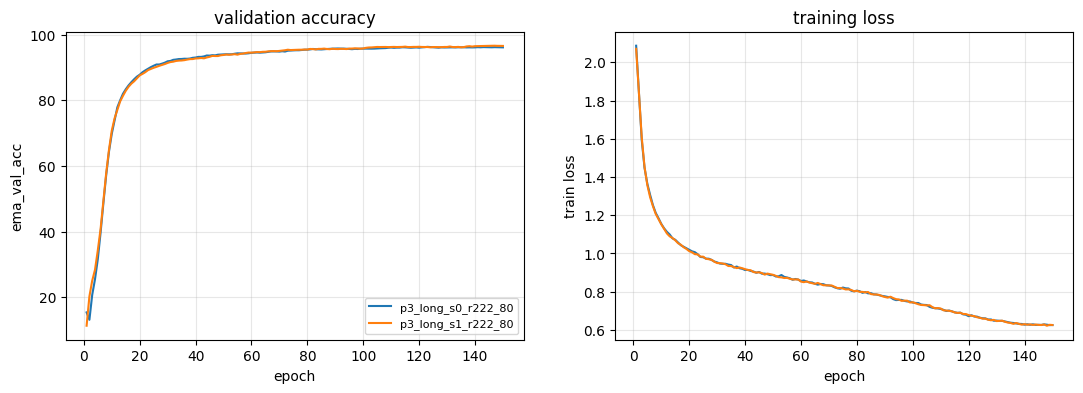

In [14]:
BEST_REG_CFG = dict(policy='autoaugment', cutout=16, ema=True)   # <-- set from Phase 2
E3 = 150
P3 = [make_cfg(name=f'p3_long_s{s}', phase='p3', epochs=E3, seed=s, **BEST_ARCH_CFG, **BEST_REG_CFG)
      for s in [0, 1]]
for c in P3:
    c['name'] += f'_{BEST_ARCH}'
run_grid(P3)
display(show_results('p3'))
plot_curves([c['name'] for c in P3], key='ema_val_acc' if BEST_REG_CFG.get('ema') else 'val_acc')

**Results (flip TTA)**
- `r222_80`: **96.60 / 96.98%** (seeds 0 / 1). With EMA weights that is 96.80 / 97.00%, +1.2–1.4 points over the 60-epoch run. Training accuracy (~95%, on augmented images) **stays below validation accuracy**, so even 150 epochs isn't too long.
- The `r343_64` runs from the earlier pass (`p3_long_s0`, `p3_long_s1`) reach 97.10 / 97.28%. At 150 epochs the deeper network is slightly stronger, which makes it a good **distillation teacher** (Phase 5).
- `p3_kd_s0` (an `r343_64` distilled from the WRN-28-10 alone, α = 0.5) scores 97.04%, no better than the same network without distillation. This is why Phase 5 distills from an *ensemble* of teachers instead of a single one.

## Phase 4: First final model on all 50k images → `submission.csv`

Here, we checked the full submission pipeline and got a first Kaggle submission from the non-distilled recipe. This uses the same config and epoch count as Phase 3, trained on all 50k images (train + validation). Because no images are held out, no checkpoint is picked by validation; the Phase 3 numbers are our estimate of its accuracy. Predictions use flip TTA (no extra parameters). The cell prints the **parameter count** and validates the submission format against `sample_submission.csv`.

In [15]:
FINAL_CFG = make_cfg(name=f'final_full_{BEST_ARCH}', phase='final', epochs=E3, seed=0, train_on_full=True,
                     **BEST_ARCH_CFG, **BEST_REG_CFG)
run_experiment(FINAL_CFG)
final_model, final_cfg = load_run_model(FINAL_CFG['name'])
n = count_params(final_model)
assert n <= PARAM_LIMIT
print(f'final model: {n:,} trainable params')

def write_submission(model, path, tta=True):
    probs = predict_probs(model, X_test_gpu, tta=tta)
    preds = probs.argmax(1).cpu().numpy()
    sub = pd.DataFrame({'id': TEST_IDS, 'label': preds.astype(int)})
    # format checks
    assert len(sub) == len(TEST_IDS) and sub['id'].is_unique
    assert sub['label'].between(0, 9).all()
    if SAMPLE_SUB is not None:
        assert list(sub.columns) == list(SAMPLE_SUB.columns), 'column names differ from sample_submission'
        assert set(sub['id']) == set(SAMPLE_SUB['id']), 'ids differ from sample_submission'
    sub.to_csv(path, index=False)
    print('wrote', path, '| predicted class distribution:', np.bincount(preds, minlength=10))
    return sub

sub = write_submission(final_model, os.path.join(RUNS_DIR, FINAL_CFG['name'], 'submission.csv'))
sub.to_csv('submission.csv', index=False)   # local copy for download
display(sub.head())

[skip] final_full_r222_80 already in results.csv
final model: 4,337,370 trainable params
wrote /content/drive/MyDrive/DL Project 1/project1_runs/final_full_r222_80/submission.csv | predicted class distribution: [167 218 202 207 200 214 179 204 208 201]


,id,label
0,0,6
1,1,3
2,2,3
3,3,9
4,4,3


**Result:** `final_full_r222_80` has **4,337,370 trainable parameters** (under the 5,000,000 limit). Its predicted classes are roughly uniform over the 2,000 test images (167–218 per class), as expected for a balanced test set. This submission is superseded by the distilled model in Phase 5.

## Distillation teacher: WRN-28-10 (100 epochs, trained from scratch)

A student under 5M parameters can learn from a much larger network's soft predictions. The rules allow this as long as the teacher is trained from scratch on the permitted data and only the student makes predictions. We train a Wide ResNet-28-10 (**36.5M parameters, teacher only**, `enforce_budget=False`) on the 45k split, so its validation accuracy stays honest and it can be used in validation experiments. The same cell also contains the single-teacher distillation run `p3_kd_s0` discussed in Phase 3. The saved `p3_kd_s0` is the `r343_64` version from the earlier pass; with the current `BEST_ARCH_CFG` the cell skips it because the name already exists.

In [16]:
KD_TEACHER = make_cfg(name='teacher_wrn28_10', phase='kd', arch='wrn28_10', enforce_budget=False,
                      epochs=100, policy='autoaugment', cutout=16, ema=True, save_weights=True)
run_experiment(KD_TEACHER)
display(show_results('kd'))

KD_STUDENT = make_cfg(name='p3_kd_s0', phase='p3', epochs=E3, seed=0, teacher='teacher_wrn28_10',
                      kd_alpha=0.5, kd_T=4.0, **BEST_ARCH_CFG, **BEST_REG_CFG)
run_experiment(KD_STUDENT)
display(show_results('p3'))   # compare with p3_long_s0 / s1

[skip] teacher_wrn28_10 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,best_val_acc,train_acc,sec_per_epoch
0,teacher_wrn28_10,wrn28_10,36479194,100,96.76,96.98,96.86,96.96,96.88,95.52,105.62


[skip] p3_kd_s0 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,best_val_acc,train_acc,sec_per_epoch
0,p3_long_s1,r343_64,4623178,150,96.82,97.28,96.78,97.26,96.84,95.14,18.48
1,p3_kd_s0,r343_64,4623178,150,96.72,97.04,96.68,97.06,96.76,95.02,48.10
2,p3_long_s0,r343_64,4623178,150,96.66,97.10,96.64,97.12,96.68,95.14,18.00
3,p3_long_s1_r222_80,r222_80,4337370,150,96.56,96.98,96.56,97.00,96.58,95.04,20.28
4,p3_long_s0_r222_80,r222_80,4337370,150,96.04,96.60,96.12,96.80,96.20,95.14,19.97


**Result:** the WRN-28-10 reaches 96.96% (EMA, flip TTA) after 100 epochs, at 106 s/epoch (about 5–6× slower than the student). Despite having 8× more parameters, it doesn't beat the `r343_64` teachers (97.10 / 97.28%) on its own. Its value is as a *different* model in the teacher ensemble.

## Phase 5: SAM, ensemble-teacher distillation, multi-crop TTA (150 epochs)

The student still underfits after 150 epochs. We try three ways to get more out of the same 4.34M parameters without adding any at prediction time:
- **Sharpness-aware minimization (SAM, ρ = 0.05):** looks for flatter minima, at twice the cost per step.
- **Knowledge distillation from a teacher ensemble:** the student matches the averaged, temperature-softened (T = 4) predictions of the teachers. Loss = 0.3 · label-smoothed CE + 0.7 · T² · KL. Each augmented batch passes through every teacher, so the targets match what the student sees.
- **Multi-crop TTA:** averages 10 views at test time.

**Step 1** checks that a teacher ensemble is actually stronger than one model (otherwise distillation is pointless) and whether multi-crop TTA beats flip TTA. **Step 2** runs single-seed 150-epoch students. We keep a change only if it clearly beats both Phase 3 seeds. **Step 3** retrains the winner on all 50k images and writes the submission.

All teachers were trained on the 45k split, so their validation numbers are honest.

In [17]:
def ensemble_val_acc(names, tta=True):
    # sanity check before distilling: is the teacher ensemble actually stronger than one student?
    # Only meaningful for runs trained on the 45k split (they have not seen the val images).
    x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
    acc = lambda p: (p.argmax(1) == y_val).float().mean().item() * 100
    probs = {}
    for n in names:
        m, c = load_run_model(n)
        assert not c['train_on_full'], f'{n} was trained on the val images, its val accuracy is meaningless'
        probs[n] = predict_probs(m, x_val, tta=tta)
        print(f'{n:22s} {acc(probs[n]):.2f}')
        del m
    print(f"{'ENSEMBLE':22s} {acc(sum(probs.values())):.2f}")

In [18]:
# Step 1: teacher-ensemble strength and multi-crop TTA, using existing models
TEACHERS_3 = ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10']
TEACHERS_2 = ['p3_long_s0', 'p3_long_s1']
ensemble_val_acc(TEACHERS_3)
ensemble_val_acc(TEACHERS_2)

x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
for n in TEACHERS_2:
    m, _ = load_run_model(n)
    print(f"{n}: flip TTA {accuracy(m, x_val, y_val, tta=True):.2f} | multi-crop TTA {accuracy(m, x_val, y_val, tta='multi'):.2f}")

# quick functional test of the new code paths (1 epoch on a subset, not logged)
_ = run_experiment(make_cfg(name='smoke_sam_kd', subset=4096, epochs=1, warmup_epochs=0,
                            sam_rho=0.05, teacher=TEACHERS_2, log=False))

p3_long_s0             97.08
p3_long_s1             97.28
teacher_wrn28_10       96.96
ENSEMBLE               97.54
p3_long_s0             97.08
p3_long_s1             97.28
ENSEMBLE               97.34
p3_long_s0: flip TTA 97.08 | multi-crop TTA 97.20
p3_long_s1: flip TTA 97.28 | multi-crop TTA 97.38
[run] smoke_sam_kd: 2,777,674 params, 1 epochs, 16 steps/epoch


smoke_sam_kd:   0%|          | 0/1 [00:00<?, ?it/s]

{'name': 'smoke_sam_kd', 'phase': '', 'notes': '', 'arch': 'r222_64', 'params': 2777674, 'epochs': 1, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 1.39, 'train_acc': 17.02, 'val_acc': 20.24, 'val_acc_tta': 20.38, 'best_val_acc': 20.24, 'best_epoch': 1, 'final_val_acc_mtta': 20.2, 'timestamp': '2026-11-11T22:26:59'}


**Step 1 results (flip TTA)**
- The 3-model ensemble (2 × `r343_64` + WRN-28-10) reaches **97.54%**, above any single teacher (96.96–97.28%), so distilling from the ensemble is worthwhile. The 2-model ensemble reaches 97.34%.
- Multi-crop TTA adds **+0.1 points** over flip TTA on both teachers (97.08 → 97.20 and 97.28 → 97.38), at no parameter cost, so we adopt it for evaluation and submission.
- The smoke run confirms that the SAM and distillation code paths work.

In [19]:
# Step 2: comment out the runs you don't want. Order = cheapest first.
E5 = E3
P5 = [
    make_cfg(name='p5_sam05',     phase='p5', epochs=E5, **BEST_ARCH_CFG, **BEST_REG_CFG, sam_rho=0.05,
             notes='SAM rho=0.05'),
    make_cfg(name='p5_kd_ens2',   phase='p5', epochs=E5, **BEST_ARCH_CFG, **BEST_REG_CFG,
             teacher=TEACHERS_2, kd_alpha=0.7, kd_T=4.0, notes='KD from 2 student seeds'),
    make_cfg(name='p5_kd_ens3',   phase='p5', epochs=E5, **BEST_ARCH_CFG, **BEST_REG_CFG,
             teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0, notes='KD from 2 seeds + WRN-28-10'),
    # run this one only after the two above, using whichever teacher set did better:
    # make_cfg(name='p5_kd_ens3_sam', phase='p5', epochs=E5, **BEST_ARCH_CFG, **BEST_REG_CFG,
    #          teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0, sam_rho=0.05, notes='KD ens3 + SAM'),
]
for c in P5: c['name'] += f'_{BEST_ARCH}'   # e.g. p5_sam05_wrn22_4 -> no clash with earlier runs
run_grid(P5)

# compare against the Phase 3 baselines (all architectures; the arch column tells them apart)
display(pd.concat([show_results('p3'), show_results('p5')]).sort_values('val_acc', ascending=False))

[skip] p5_sam05_r222_80 already in results.csv
[skip] p5_kd_ens2_r222_80 already in results.csv
[skip] p5_kd_ens3_r222_80 already in results.csv


,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,best_val_acc,train_acc,sec_per_epoch,final_val_acc_mtta,notes
1,p5_kd_ens3_r222_80,r222_80,4337370,150,96.88,97.10,96.86,97.06,97.00,94.95,7.85,97.00,KD from 2 seeds + WRN-28-10
0,p5_kd_ens2_r222_80,r222_80,4337370,150,96.88,97.40,96.94,97.46,97.00,95.22,7.96,97.34,KD from 2 student seeds
0,p3_long_s1,r343_64,4623178,150,96.82,97.28,96.78,97.26,96.84,95.14,18.48,NaN,NaN
1,p3_kd_s0,r343_64,4623178,150,96.72,97.04,96.68,97.06,96.76,95.02,48.10,NaN,NaN
2,p3_long_s0,r343_64,4623178,150,96.66,97.10,96.64,97.12,96.68,95.14,18.00,NaN,NaN
3,p3_long_s1_r222_80,r222_80,4337370,150,96.56,96.98,96.56,97.00,96.58,95.04,20.28,NaN,NaN
2,p5_sam05_r222_80,r222_80,4337370,150,96.56,96.90,96.64,96.82,96.76,95.01,8.01,96.94,SAM rho=0.05
4,p3_long_s0_r222_80,r222_80,4337370,150,96.04,96.60,96.12,96.80,96.20,95.14,19.97,NaN,NaN


**Step 2 results (student `r222_80`, 150 epochs, multi-crop TTA)**

| Run | Val acc (%) |
|---|---|
| No distillation (Phase 3, flip TTA) | 96.60 / 96.98 |
| SAM, ρ = 0.05 | 96.94 |
| KD from 2 teachers (2 × `r343_64`) | 97.34 |
| KD from 3 teachers (+ WRN-28-10) | 97.00 |

- **Distillation lifts the 4.34M student to roughly the level of its 4.6M–36.5M teachers.**
- SAM costs twice the compute for no clear gain, so we drop it.
- The 2-teacher student scores higher than the 3-teacher one on this single seed, but the gap (0.34) is at the edge of seed noise, and the 3-teacher ensemble is the stronger teacher (97.54 vs. 97.34). We kept 3 teachers. Phase 6 adds a second seed of the 3-teacher recipe (97.14).

**Decision:** `P5_WINNER = KD from 3 teachers (α = 0.7, T = 4)`, submitted with multi-crop TTA.

In [20]:
# Step 3: retrain the winner on all 50k and write a new submission.
# Copy the winning extras here, e.g. dict(sam_rho=0.05) or dict(teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0)
P5_WINNER = dict(teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0)   # <-- set from the Step 2 table
SUB_TTA = 'multi'                                               # <-- or True if multi-crop did not help in Step 1

FINAL5 = make_cfg(name=f'final_full_p5_{BEST_ARCH}', phase='final', epochs=E5, seed=0, train_on_full=True,
                  **BEST_ARCH_CFG, **BEST_REG_CFG, **P5_WINNER)
run_experiment(FINAL5)
final5, _ = load_run_model(FINAL5['name'])
n = count_params(final5)
assert n <= PARAM_LIMIT
print(f"{FINAL5['name']}: {n:,} trainable params")

sub5 = write_submission(final5, os.path.join(RUNS_DIR, FINAL5['name'], 'submission.csv'), tta=SUB_TTA)
sub5.to_csv(f'submission_p5_{BEST_ARCH}.csv', index=False)   # local copy for download

[skip] final_full_p5_r222_80 already in results.csv
final_full_p5_r222_80: 4,337,370 trainable params
wrote /content/drive/MyDrive/DL Project 1/project1_runs/final_full_p5_r222_80/submission.csv | predicted class distribution: [171 216 212 208 197 215 177 199 201 204]


**Step 3 result: our first submission.** `final_full_p5_r222_80` is the 3-teacher distilled `r222_80` trained on all 50k images for 150 epochs. It has **4,337,370 trainable parameters** and scored **0.887 on the public and 0.857 on the private Kaggle leaderboard**. Our final variants A and B (separate notebooks) both start from this recipe.

## Phase 6: Class-targeted training vs. a stronger teacher ensemble (150 epochs, 2 seeds)

The error analysis below shows that **cat and dog are by far the weakest classes** (~93–95% vs. 96–99% for the others). We test whether targeting them helps overall accuracy, using the current best recipe (`r222_80`, AutoAugment + Cutout + EMA, distilled from 3 teachers):
- **oversampling** cat/dog images 1.5×;
- **weighting** their loss 1.5×;
- as an alternative, a **stronger 5-model teacher ensemble** (the 3 teachers + the two Phase 5 students).

We use two seeds per variant, because the expected effects are small. We compare per-class as well as overall accuracy: the question is whether other classes pay for the cat/dog gains.

In [21]:
CAT, DOG = 3, 5
KD3 = dict(teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0)
TEACHERS_5 = TEACHERS_3 + ['p5_kd_ens2_r222_80', 'p5_kd_ens3_r222_80']   # all trained on the 45k split
ensemble_val_acc(TEACHERS_5)        # the run is worth it if this beats the 3-model ensemble (97.54)
KD5 = dict(teacher=TEACHERS_5, kd_alpha=0.7, kd_T=4.0)

base = dict(phase='p6', epochs=E5, **BEST_ARCH_CFG, **BEST_REG_CFG)
P6 = [
    # second seed of the current best recipe (seed 0 = p5_kd_ens3_r222_80)
    make_cfg(name='p6_kd3_s1', seed=1, **base, **KD3, notes='KD ens3 baseline, seed 1'),
    # class-targeted training
    make_cfg(name='p6_kd3_os15_s0', seed=0, **base, **KD3, oversample={CAT: 1.5, DOG: 1.5}, notes='oversample cat/dog x1.5'),
    make_cfg(name='p6_kd3_os15_s1', seed=1, **base, **KD3, oversample={CAT: 1.5, DOG: 1.5}, notes='oversample cat/dog x1.5'),
    make_cfg(name='p6_kd3_cw15_s0', seed=0, **base, **KD3, class_weights={CAT: 1.5, DOG: 1.5}, notes='loss weight cat/dog x1.5'),
    make_cfg(name='p6_kd3_cw15_s1', seed=1, **base, **KD3, class_weights={CAT: 1.5, DOG: 1.5}, notes='loss weight cat/dog x1.5'),
    # stronger teacher
    make_cfg(name='p6_kd5_s0', seed=0, **base, **KD5, notes='KD from 5-model ensemble'),
    make_cfg(name='p6_kd5_s1', seed=1, **base, **KD5, notes='KD from 5-model ensemble'),
]
for c in P6: c['name'] += f'_{BEST_ARCH}'
run_grid(P6)

p3_long_s0             97.08
p3_long_s1             97.28
teacher_wrn28_10       96.96
p5_kd_ens2_r222_80     97.46
p5_kd_ens3_r222_80     97.06
ENSEMBLE               97.56
[skip] p6_kd3_s1_r222_80 already in results.csv
[skip] p6_kd3_os15_s0_r222_80 already in results.csv
[skip] p6_kd3_os15_s1_r222_80 already in results.csv
[skip] p6_kd3_cw15_s0_r222_80 already in results.csv
[skip] p6_kd3_cw15_s1_r222_80 already in results.csv
[skip] p6_kd5_s0_r222_80 already in results.csv
[skip] p6_kd5_s1_r222_80 already in results.csv


In [22]:
def per_class_table(names, tta=True):
    # val accuracy overall and per class for each run (EMA weights if the run used EMA)
    x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
    rows = []
    for n in names:
        m, _ = load_run_model(n)
        p = predict_probs(m, x_val, tta=tta).argmax(1)
        r = {'run': n, 'overall': (p == y_val).float().mean().item() * 100}
        for c in range(10):
            r[CLASSES[c]] = ((p == c) & (y_val == c)).sum().item() / (y_val == c).sum().item() * 100
        rows.append(r)
        del m
    return pd.DataFrame(rows).round(2)

groups = {
    'KD ens3 (baseline)':  ['p5_kd_ens3_r222_80', 'p6_kd3_s1_r222_80'],
    'oversample cat/dog':  ['p6_kd3_os15_s0_r222_80', 'p6_kd3_os15_s1_r222_80'],
    'loss weight cat/dog': ['p6_kd3_cw15_s0_r222_80', 'p6_kd3_cw15_s1_r222_80'],
    'KD ens5':             ['p6_kd5_s0_r222_80', 'p6_kd5_s1_r222_80'],
}
tbl = per_class_table([n for runs in groups.values() for n in runs])
tbl.insert(0, 'variant', [g for g, runs in groups.items() for _ in runs])
display(tbl)
display(tbl.drop(columns='run').groupby('variant', sort=False).mean().round(2))   # 2-seed means
tbl.to_csv(os.path.join(RUNS_DIR, 'p6_per_class.csv'), index=False)

,variant,run,overall,plane,car,bird,cat,deer,dog,frog,horse,ship,truck
0,KD ens3 (baseline),p5_kd_ens3_r222_80,97.06,97.0,98.4,96.2,94.8,98.0,92.8,98.0,97.8,98.2,99.4
1,KD ens3 (baseline),p6_kd3_s1_r222_80,97.14,98.0,98.2,95.6,95.0,98.2,92.4,98.2,98.0,98.6,99.2
2,oversample cat/dog,p6_kd3_os15_s0_r222_80,96.94,97.6,98.6,96.0,93.8,98.0,93.4,97.6,97.4,98.4,98.6
3,oversample cat/dog,p6_kd3_os15_s1_r222_80,97.14,98.0,98.2,96.2,93.8,98.6,93.0,97.6,98.2,98.8,99.0
4,loss weight cat/dog,p6_kd3_cw15_s0_r222_80,97.14,97.6,98.2,96.2,94.6,98.2,93.6,97.4,98.4,98.4,98.8
5,loss weight cat/dog,p6_kd3_cw15_s1_r222_80,97.06,98.2,98.0,96.2,93.8,97.8,93.8,97.8,98.2,98.2,98.6
6,KD ens5,p6_kd5_s0_r222_80,97.10,98.0,98.0,96.6,94.8,98.0,92.0,98.0,98.4,98.8,98.4
7,KD ens5,p6_kd5_s1_r222_80,97.30,97.6,98.6,96.2,94.4,98.6,93.2,97.6,98.6,99.2,99.0


,overall,plane,car,bird,cat,deer,dog,frog,horse,ship,truck
variant,,,,,,,,,,,
KD ens3 (baseline),97.10,97.5,98.3,95.9,94.9,98.1,92.6,98.1,97.9,98.4,99.3
oversample cat/dog,97.04,97.8,98.4,96.1,93.8,98.3,93.2,97.6,97.8,98.6,98.8
loss weight cat/dog,97.10,97.9,98.1,96.2,94.2,98.0,93.7,97.6,98.3,98.3,98.7
KD ens5,97.20,97.8,98.3,96.4,94.6,98.3,92.6,97.8,98.5,99.0,98.7


**Results (2-seed means, flip TTA)**

| Variant | Overall | Cat | Dog |
|---|---|---|---|
| KD 3 teachers (baseline) | 97.10 | 94.9 | 92.6 |
| Oversample cat/dog ×1.5 | 97.04 | 93.8 | 93.2 |
| Loss weight cat/dog ×1.5 | 97.10 | 94.2 | 93.7 |
| KD 5 teachers | 97.20 | 94.6 | 92.6 |

- Class targeting **trades accuracy between classes without improving the total.** Dog improves by up to 1.1 points, but cat and other classes (frog, truck) drop. Most cat/dog errors are confusions *with each other*, so pushing one class pulls the other.
- The 5-model ensemble (97.56%) is no stronger than the 3-model one (97.54%), and the student's +0.1 is within noise.

**Decision:** no class reweighting; keep the 3-teacher recipe.

## Where does the model fail, and why is test accuracy lower?

Every submitted model scored about **97% on validation but about 86–89% on the Kaggle test set**. The cells below look into this gap. Test images are only *described* here (statistics, confidence, agreement between models), never used to change the model.

**Teacher check:** reload the WRN-28-10 teacher and confirm its parameter count and validation accuracy.

In [23]:
wrn, wrn_cfg = load_run_model('teacher_wrn28_10')   # or 'p1_wrn22_4', 'p1_wrn16_4'
print(f'{count_params(wrn):,} params')

# validation (the teacher was trained on the 45k split, so these images are unseen)
val_probs = predict_probs(wrn, X_all_gpu[VAL_IDX], tta=True)
print('val acc (flip TTA): %.2f' % ((val_probs.argmax(1) == Y_all_gpu[VAL_IDX]).float().mean().item() * 100))

# test-set predictions
test_probs = predict_probs(wrn, X_test_gpu, tta=True)          # (N_test, 10) probabilities
test_preds = test_probs.argmax(1).cpu().numpy()                 # class indices 0-9

36,479,194 params
val acc (flip TTA): 96.96


**Test-set statistics vs. training images:** per-channel mean and standard deviation, an edge-energy ratio (above 1 means sharper), mean prediction confidence, and a sample of training (top) vs. test (bottom) images.

n test images: 2000
mean  train [0.48933154344558716, 0.48057255148887634, 0.44305863976478577] 
      test  [0.5129620432853699, 0.49779853224754333, 0.4612242877483368]
std   train [0.24560923874378204, 0.24154923856258392, 0.2601666748523712] 
      test  [0.26484397053718567, 0.2622224688529968, 0.27506229281425476]
edge energy (blur < 1 < noise)  test/train ratio: 1.08
mean confidence  val 0.887 | test 0.843
predicted class distribution on test (%): [ 8.6 10.6 10.4 10.  10.  10.8  9.4  9.9 10.4  9.8]


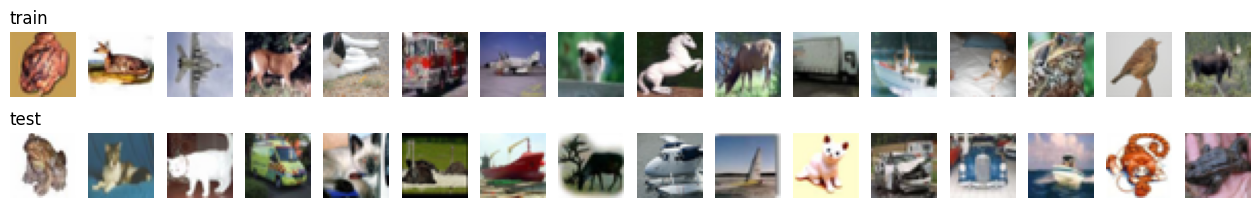

In [24]:
m, _ = load_run_model('p3_long_s0')
xtr = X_all_gpu[TRAIN_IDX[:5000]].float() / 255
xte = X_test_gpu[:5000].float() / 255
edge = lambda x: (x.mean(1).diff(dim=1).abs().mean() + x.mean(1).diff(dim=2).abs().mean()).item()
print('n test images:', len(X_test_gpu))
print('mean  train', xtr.mean((0,2,3)).tolist(), '\n      test ', xte.mean((0,2,3)).tolist())
print('std   train', xtr.std((0,2,3)).tolist(),  '\n      test ', xte.std((0,2,3)).tolist())
print('edge energy (blur < 1 < noise)  test/train ratio: %.2f' % (edge(xte) / edge(xtr)))

pv = predict_probs(m, X_all_gpu[VAL_IDX], tta=True)
pt = predict_probs(m, X_test_gpu, tta=True)
print('mean confidence  val %.3f | test %.3f' % (pv.max(1).values.mean(), pt.max(1).values.mean()))
print('predicted class distribution on test (%):', np.round(np.bincount(pt.argmax(1).cpu().numpy(), minlength=10) / len(pt) * 100, 1))

fig, ax = plt.subplots(2, 16, figsize=(16, 2.4))
for i in range(16):
    ax[0, i].imshow(xtr[i].permute(1, 2, 0).cpu()); ax[1, i].imshow(xte[i].permute(1, 2, 0).cpu())
    ax[0, i].axis('off'); ax[1, i].axis('off')
ax[0, 0].set_title('train', loc='left'); ax[1, 0].set_title('test', loc='left'); plt.show()

**Results:** the test images are **brighter** (mean +0.02 in every channel), **higher in contrast** (std ×1.08) and **slightly sharper** (edge energy ×1.08) than the training images. The model is **less confident on test** (0.843 vs. 0.887). Its predicted classes on test are close to uniform (8.6–10.8% each), so the gap isn't caused by one class collapsing. These measured shifts are the basis for the "test-like" validation images in Phase 7.

### Weakness analysis
**A. Validation** (true labels available): per-class accuracy, confusions, calibration, and the most confident errors of `p5_kd_ens3_r222_80`. It is trained exactly like the submitted model, but on the 45k split, so it hasn't seen the validation images.

**B. Test** (no labels): agreement with the submission, confidence per class compared with validation, and disagreement between independently trained models.

p5_kd_ens3_r222_80: val acc 97.00%  (150 errors / 5000)

per-class accuracy (worst first):
  dog     92.6%
  cat     93.8%
  bird    96.4%
  plane   97.6%
  horse   97.6%
  frog    98.0%
  deer    98.2%
  car     98.4%
  ship    98.4%
  truck   99.0%

most common confusions (true -> predicted):
  dog    -> cat    28
  cat    -> dog    21
  bird   -> plane  7
  horse  -> deer   7
  dog    -> deer   6
  plane  -> ship   6
  bird   -> cat    4
  bird   -> dog    4
  cat    -> deer   4
  ship   -> car    4


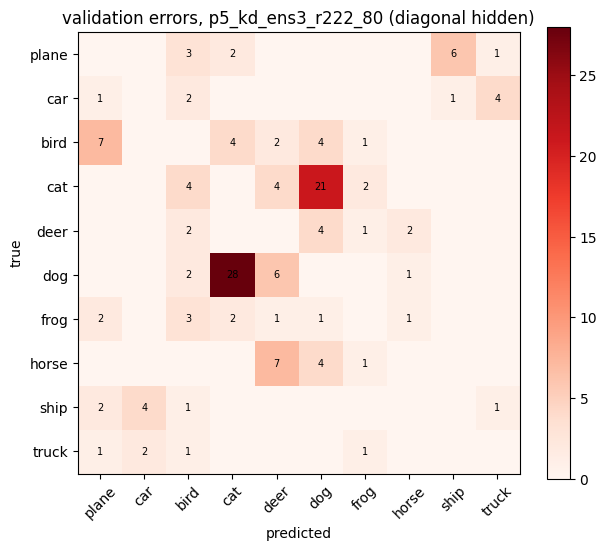


confidence bin     n   accuracy   mean conf
  0.00-0.50    100     51.0%      41.7%
  0.50-0.70    184     71.7%      60.7%
  0.70-0.80    159     88.7%      75.3%
  0.80-0.90    848     97.3%      87.6%
  0.90-0.95   3687     99.8%      91.5%
  0.95-1.00     22    100.0%      95.8%


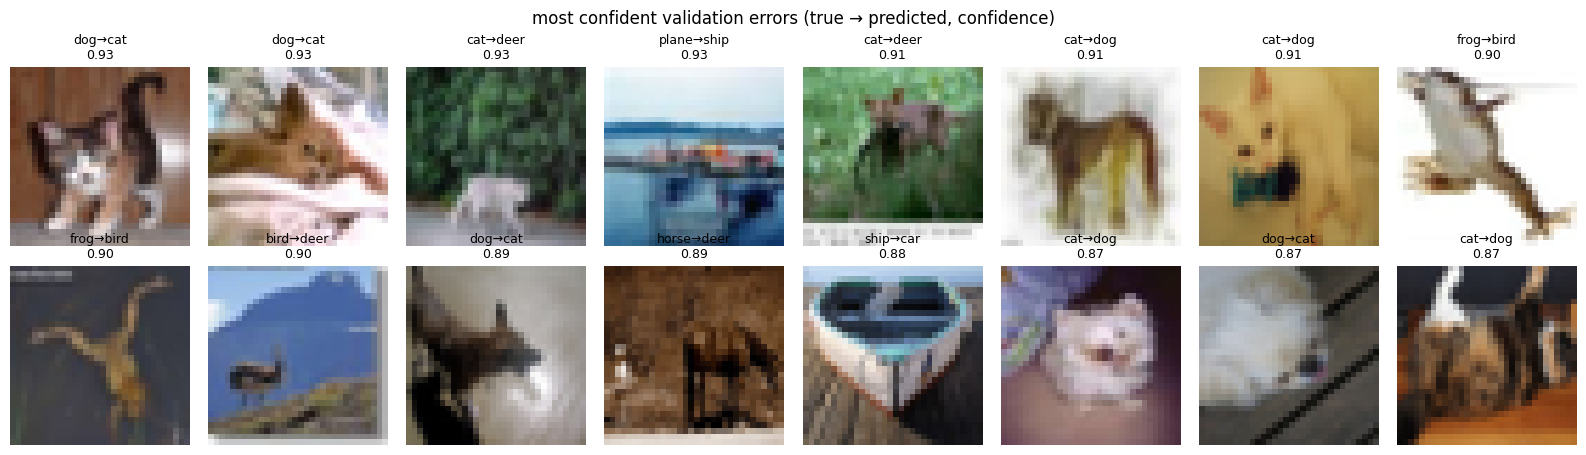

In [25]:
# ---- A. Validation error analysis ----
ANALYSIS_RUN = 'p5_kd_ens3_r222_80'     # same recipe as the submission, trained on 45k (val images unseen)
ANALYSIS_TTA = 'multi'                  # same TTA as the submission

m_an, _ = load_run_model(ANALYSIS_RUN)
x_val, y_val = X_all_gpu[VAL_IDX], Y_all_gpu[VAL_IDX]
pv = predict_probs(m_an, x_val, tta=ANALYSIS_TTA).cpu()
yv = y_val.cpu()
pred_v, conf_v = pv.argmax(1), pv.max(1).values
wrong_v = pred_v != yv
print(f'{ANALYSIS_RUN}: val acc {100 - wrong_v.float().mean().item() * 100:.2f}%  '
      f'({int(wrong_v.sum())} errors / {len(yv)})')

# confusion matrix and per-class accuracy
cm = torch.zeros(10, 10, dtype=torch.long)
cm.index_put_((yv, pred_v), torch.ones_like(yv), accumulate=True)
per_class_acc = (cm.diag().float() / cm.sum(1).float() * 100)
print('\nper-class accuracy (worst first):')
for c in per_class_acc.argsort().tolist():
    print(f'  {CLASSES[c]:6s} {per_class_acc[c].item():5.1f}%')

off = cm.clone(); off.fill_diagonal_(0)
vals, idx = off.flatten().topk(10)
print('\nmost common confusions (true -> predicted):')
for v, i in zip(vals.tolist(), idx.tolist()):
    if v > 0:
        print(f'  {CLASSES[i // 10]:6s} -> {CLASSES[i % 10]:6s} {v}')

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(off.numpy(), cmap='Reds')
ax.set_xticks(range(10)); ax.set_xticklabels(CLASSES, rotation=45)
ax.set_yticks(range(10)); ax.set_yticklabels(CLASSES)
ax.set_xlabel('predicted'); ax.set_ylabel('true')
ax.set_title(f'validation errors, {ANALYSIS_RUN} (diagonal hidden)')
for i in range(10):
    for j in range(10):
        if off[i, j] > 0:
            ax.text(j, i, int(off[i, j]), ha='center', va='center', fontsize=7)
plt.colorbar(im); plt.tight_layout(); plt.show()

# calibration: is "90% confident" right 90% of the time?
edges = [0, .5, .7, .8, .9, .95, 1.01]
print('\nconfidence bin     n   accuracy   mean conf')
for lo, hi in zip(edges[:-1], edges[1:]):
    s = (conf_v >= lo) & (conf_v < hi)
    if s.any():
        print(f'  {lo:.2f}-{min(hi, 1):.2f}  {int(s.sum()):5d}    {100 - wrong_v[s].float().mean().item() * 100:5.1f}%     '
              f'{conf_v[s].mean().item() * 100:5.1f}%')

# the 16 most confident mistakes (often label noise or genuinely ambiguous images)
err_idx = torch.where(wrong_v)[0]
order = err_idx[conf_v[err_idx].argsort(descending=True)][:16].tolist()
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for a, i in zip(ax.flat, order):
    a.imshow(x_val[i].permute(1, 2, 0).cpu()); a.axis('off')
    a.set_title(f'{CLASSES[int(yv[i])]}→{CLASSES[int(pred_v[i])]}\n{conf_v[i].item():.2f}', fontsize=9)
for a in list(ax.flat)[len(order):]:
    a.axis('off')
plt.suptitle('most confident validation errors (true → predicted, confidence)'); plt.tight_layout(); plt.show()

**Results (A, validation)**
- 97.00% accuracy (150 errors out of 5,000). **Dog (92.6%) and cat (93.8%) are the weakest classes**; every other class is at 96.4% or above.
- The two most common errors are **dog → cat (28) and cat → dog (21)**, a third of all errors. Next come look-alike pairs: bird → plane, horse → deer, plane → ship.
- **Calibration:** the model is *under*-confident on validation. For example, predictions with 90–95% confidence are right 99.8% of the time. This is expected with label smoothing and distillation, which both soften the outputs.
- The image grid shows the 16 most confident mistakes, with their true and predicted classes.

agreement with final_full_p5_r222_80/submission.csv: 95.5%
mean confidence  val 0.882 | test 0.836
models disagree on 2.2% of val images vs 6.8% of test images


,cls,val_acc,top_confusion,val_conf,test_conf,conf_drop,val_disagree_pct,test_disagree_pct,test_pred_share_pct
0,dog,92.6,cat (28),0.860,0.833,0.027,4.4,7.0,10.8
1,cat,93.8,dog (21),0.855,0.770,0.086,5.7,14.9,10.4
2,bird,96.4,plane (7),0.873,0.835,0.038,2.6,5.3,10.4
3,plane,97.6,ship (6),0.885,0.813,0.072,1.4,7.8,8.3
4,horse,97.6,deer (7),0.894,0.856,0.038,1.0,3.4,10.1
5,frog,98.0,bird (3),0.891,0.857,0.033,1.8,5.0,9.0
6,deer,98.2,dog (4),0.879,0.847,0.032,2.0,5.1,9.7
7,car,98.4,truck (4),0.899,0.846,0.054,0.8,6.4,10.9
8,ship,98.4,car (4),0.894,0.861,0.033,0.8,5.4,10.2
9,truck,99.0,car (2),0.895,0.838,0.058,1.4,7.4,10.1


saved /content/drive/MyDrive/DL Project 1/project1_runs/weakness_analysis.csv


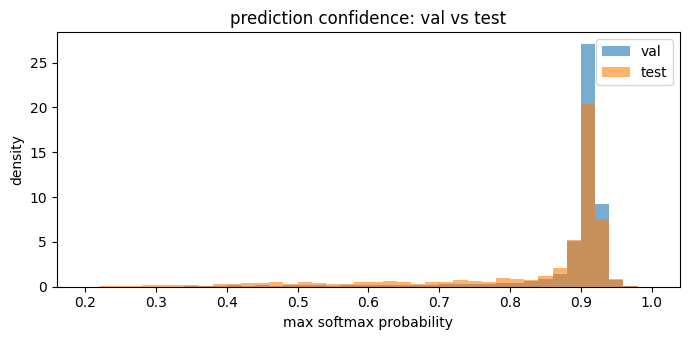

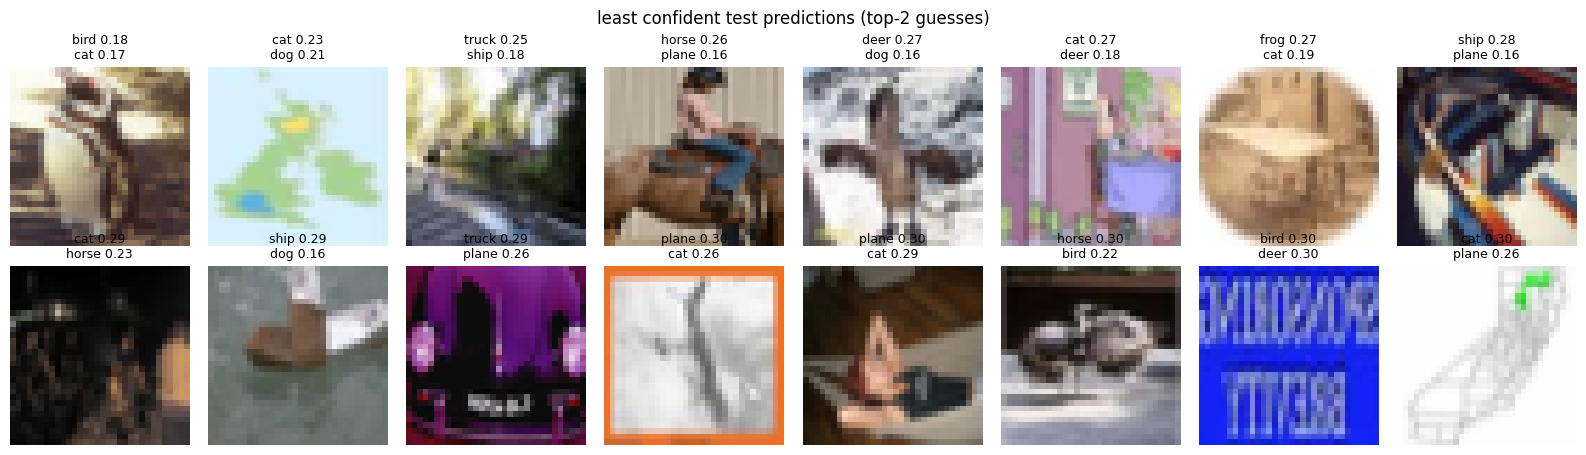

In [26]:
# ---- B. Test-set analysis (no labels: describes the shift, never used to change the model) ----
SUBMISSION_RUN = 'final_full_p5_r222_80'                    # the submission you uploaded
COMPARE_RUNS = ['p5_kd_ens2_r222_80', 'p3_long_s1']         # independently trained strong models

pt = predict_probs(m_an, X_test_gpu, tta=ANALYSIS_TTA).cpu()
pred_t, conf_t = pt.argmax(1), pt.max(1).values

# 1) agreement with the submitted predictions (expect ~95-97%: the submission model also trained on val)
sub_best = pd.read_csv(os.path.join(RUNS_DIR, SUBMISSION_RUN, 'submission.csv'))
assert (sub_best['id'].values == TEST_IDS).all(), 'submission ids are not in test.csv order'
print(f'agreement with {SUBMISSION_RUN}/submission.csv: '
      f'{(sub_best["label"].values == pred_t.numpy()).mean() * 100:.1f}%')
print(f'mean confidence  val {conf_v.mean().item():.3f} | test {conf_t.mean().item():.3f}')

# 2) disagreement between independently trained models: an unsupervised error signal
preds_all = torch.stack([pred_t] + [predict_probs(load_run_model(n)[0], X_test_gpu, tta=ANALYSIS_TTA).cpu().argmax(1)
                                    for n in COMPARE_RUNS])
disagree_t = (preds_all != preds_all[0]).any(0)
preds_all_v = torch.stack([pred_v] + [predict_probs(load_run_model(n)[0], x_val, tta=ANALYSIS_TTA).cpu().argmax(1)
                                      for n in COMPARE_RUNS])
disagree_v = (preds_all_v != preds_all_v[0]).any(0)
print(f'models disagree on {disagree_v.float().mean().item() * 100:.1f}% of val images '
      f'vs {disagree_t.float().mean().item() * 100:.1f}% of test images')

# 3) per-class summary (classes are grouped by *predicted* label for both val and test, so they compare like with like)
rows = []
for c in range(10):
    sv, st = pred_v == c, pred_t == c
    top_conf = off[c].argmax().item()
    rows.append(dict(
        cls=CLASSES[c],
        val_acc=round(per_class_acc[c].item(), 1),
        top_confusion=f'{CLASSES[top_conf]} ({int(off[c, top_conf])})',
        val_conf=round(conf_v[sv].mean().item(), 3),
        test_conf=round(conf_t[st].mean().item(), 3) if st.any() else float('nan'),
        conf_drop=round(conf_v[sv].mean().item() - conf_t[st].mean().item(), 3) if st.any() else float('nan'),
        val_disagree_pct=round(disagree_v[sv].float().mean().item() * 100, 1),
        test_disagree_pct=round(disagree_t[st].float().mean().item() * 100, 1) if st.any() else float('nan'),
        test_pred_share_pct=round(st.float().mean().item() * 100, 1),
    ))
summary = pd.DataFrame(rows).sort_values('val_acc').reset_index(drop=True)
display(summary)
summary_path = os.path.join(RUNS_DIR, 'weakness_analysis.csv')
summary.to_csv(summary_path, index=False)
print('saved', summary_path)

# 4) confidence histograms, val vs test
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.hist(conf_v.numpy(), bins=40, range=(0.2, 1), alpha=.6, density=True, label='val')
ax.hist(conf_t.numpy(), bins=40, range=(0.2, 1), alpha=.6, density=True, label='test')
ax.set(xlabel='max softmax probability', ylabel='density', title='prediction confidence: val vs test')
ax.legend(); plt.tight_layout(); plt.show()

# 5) the 16 least confident test predictions with their top-2 guesses
order = conf_t.argsort()[:16].tolist()
top2 = pt.topk(2, 1)
fig, ax = plt.subplots(2, 8, figsize=(16, 4.6))
for a, i in zip(ax.flat, order):
    a.imshow(X_test[i].permute(1, 2, 0)); a.axis('off')
    a.set_title(f'{CLASSES[int(top2.indices[i, 0])]} {top2.values[i, 0].item():.2f}\n'
                f'{CLASSES[int(top2.indices[i, 1])]} {top2.values[i, 1].item():.2f}', fontsize=9)
plt.suptitle('least confident test predictions (top-2 guesses)'); plt.tight_layout(); plt.show()

**Results (B, test, no labels)**
- The validation-split model agrees with the submitted predictions on 95.5% of test images.
- Mean confidence drops from **0.882 on validation to 0.836 on test**. Cat drops the most (0.855 → 0.770).
- **Independently trained models disagree on 6.8% of test images vs. 2.2% of validation images**, three times as often, and on 14.9% of test images predicted as cat.

Together, these suggest the test set contains *harder content*: more ambiguous animals, unusual poses and look-alike classes. Phase 7 tests the alternative explanation, that the test images simply *look* different.

## Phase 7: Robustness to the test-set shift (150 epochs, 2 seeds)

The test images are brighter, higher in contrast and slightly sharper than the training images, and models disagree on them three times as often. If the gap came from these *appearance* differences, making the model robust to them should help. We measure this without touching the test images:

- **Step 1 (minutes):** build shifted copies of the **validation** images and score the existing models on them. `testlike` applies the brightness/contrast change measured above; the other shifts are larger and generic (brightness ±, contrast ±, desaturation, sharpening, blur, JPEG-50).
- **Step 2 (~2 GPU-hours):** train with photometric + blur/sharpen augmentation (2 seeds) and compare with the 5-teacher reference from Phase 6.

Model selection uses `shift_avg` (the mean over all shifts), not any single shift, so it rewards general robustness instead of tuning to the test set. Requires cell 6b.

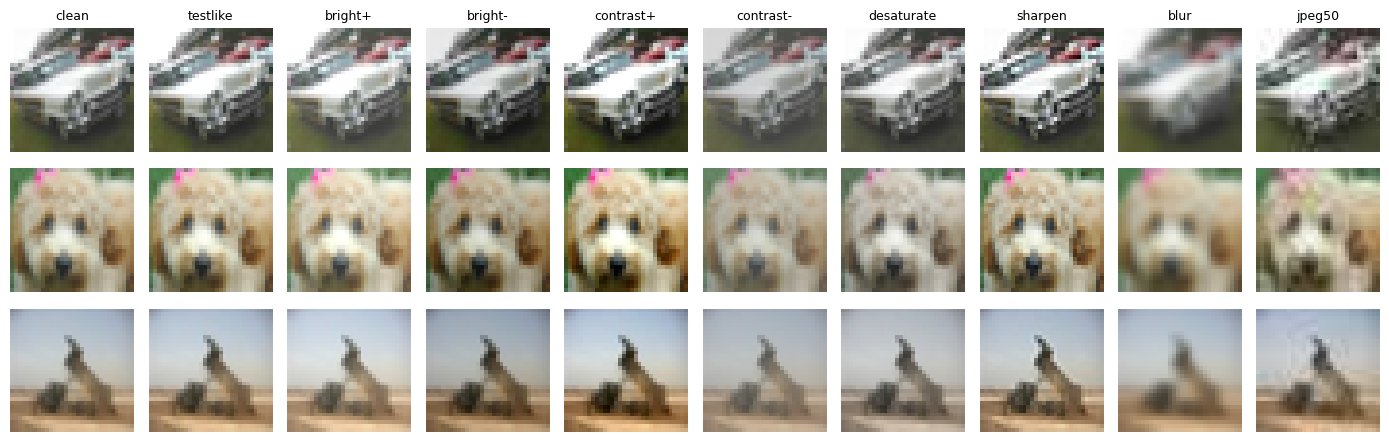

,run,clean,shift_avg,drop,testlike,bright+,bright-,contrast+,contrast-,desaturate,sharpen,blur,jpeg50
0,p6_kd5_s0_r222_80,97.20,93.82,3.38,97.24,97.10,97.20,97.14,97.02,97.10,96.86,82.00,82.70
1,p5_kd_ens2_r222_80,97.34,93.71,3.63,97.36,97.14,97.30,97.26,97.04,97.14,96.88,81.18,82.08
2,p6_kd5_s1_r222_80,97.10,93.59,3.51,97.10,96.98,97.16,97.12,96.82,96.96,96.84,81.58,81.78
3,p6_kd3_cw15_s0_r222_80,97.18,93.58,3.60,97.34,97.14,97.16,97.02,96.94,96.92,96.96,81.00,81.74
4,p5_kd_ens3_r222_80,97.00,93.54,3.46,97.08,97.14,97.02,96.94,96.94,97.04,96.60,80.56,82.50
5,p3_long_s1,97.38,93.54,3.84,97.38,97.20,97.10,97.08,97.06,97.18,96.72,79.96,82.16
6,p6_kd3_s1_r222_80,97.14,93.52,3.62,97.10,97.10,97.16,96.98,96.94,96.88,96.62,80.28,82.60
7,p3_long_s0,97.20,93.39,3.81,97.08,96.90,97.16,97.02,97.12,96.96,96.80,80.76,80.68
8,p5_sam05_r222_80,96.94,93.32,3.62,96.98,96.90,96.94,96.86,96.84,96.64,96.40,80.84,81.48
9,teacher_wrn28_10,96.94,93.14,3.80,97.04,96.90,97.08,97.04,96.92,96.96,96.70,78.94,80.66


In [27]:
# ---- Phase 7, step 1: shifted validation set + robustness evaluation of existing models ----
# Every shift is applied to the 5k VALIDATION images only; the test images are never used. 'testlike' copies
# the global brightness/contrast change already measured in cell 32 (mean about +0.02, std about x1.08). The
# other shifts are deliberately larger and generic, so model selection rewards general robustness instead
# of being tuned to the test set. Select on 'shift_avg' (mean over all shifted versions), not on 'testlike'.
Y_VAL = Y_all_gpu[VAL_IDX]

def _u8(x01):
    return (x01.clamp(0, 1) * 255).round().to(torch.uint8)

def jpeg(x_u8, quality):
    # CPU round-trip through PIL JPEG (about 2 s for 5k images)
    out = []
    for im in x_u8.cpu().permute(0, 2, 3, 1).numpy():
        buf = io.BytesIO(); Image.fromarray(im).save(buf, format='JPEG', quality=quality); buf.seek(0)
        out.append(np.asarray(Image.open(buf).convert('RGB')))
    return torch.from_numpy(np.stack(out)).permute(0, 3, 1, 2).contiguous().to(x_u8.device)

def build_shifted_val(x_u8):
    x = x_u8.float() / 255
    g = _gray(x)
    m = g.mean(dim=(1, 2, 3), keepdim=True)
    return {
        'clean':       x_u8,
        'testlike':    _u8((x - m) * 1.08 + m + 0.02),
        'bright+':     _u8(x + 0.08),
        'bright-':     _u8(x - 0.08),
        'contrast+':   _u8((x - m) * 1.3 + m),
        'contrast-':   _u8((x - m) * 0.7 + m),
        'desaturate':  _u8((x - g) * 0.5 + g),
        'sharpen':     _u8(sharpen(x, 0.8)),
        'blur':        _u8(blur_resample(x, 0.6)),
        'jpeg50':      jpeg(x_u8, 50),
    }

SHIFTED_VAL = build_shifted_val(X_all_gpu[VAL_IDX])
SHIFT_KEYS = [k for k in SHIFTED_VAL if k != 'clean']

ROBUST_CSV = os.path.join(RUNS_DIR, 'robust_eval.csv')

def robust_eval(names, tta='multi', recompute=False):
    # clean + per-shift val accuracy for each run; results are cached in robust_eval.csv
    done = (pd.read_csv(ROBUST_CSV, dtype={'tta': str}) if os.path.exists(ROBUST_CSV)
            else pd.DataFrame(columns=['run', 'tta']))
    rows = []
    for n in names:
        hit = done[(done['run'] == n) & (done['tta'] == str(tta))]
        if len(hit) and not recompute:
            rows.append(hit.iloc[-1].to_dict()); continue
        if not os.path.exists(os.path.join(RUNS_DIR, n, 'final.pt')):
            print(f'[skip] {n}: no final.pt'); continue
        m, c = load_run_model(n)
        assert not c['train_on_full'], f'{n} was trained on the val images, its val accuracy is meaningless'
        r = {'run': n, 'tta': str(tta)}
        for k, xs in SHIFTED_VAL.items():
            r[k] = round(accuracy(m, xs, Y_VAL, tta=tta), 2)
        r['shift_avg'] = round(float(np.mean([r[k] for k in SHIFT_KEYS])), 2)
        r['drop'] = round(r['clean'] - r['shift_avg'], 2)
        rows.append(r)
        done = pd.concat([done, pd.DataFrame([r])], ignore_index=True)
        done.to_csv(ROBUST_CSV, index=False)
        del m
        if device == 'cuda': torch.cuda.empty_cache()
    cols = ['run', 'clean', 'shift_avg', 'drop'] + SHIFT_KEYS
    return pd.DataFrame(rows)[cols].sort_values('shift_avg', ascending=False).reset_index(drop=True)

# what the shifts look like (one image per column)
fig, ax = plt.subplots(3, len(SHIFTED_VAL), figsize=(1.4 * len(SHIFTED_VAL), 4.6))
for j, (k, xs) in enumerate(SHIFTED_VAL.items()):
    for i in range(3):
        ax[i, j].imshow(xs[i].permute(1, 2, 0).cpu()); ax[i, j].axis('off')
    ax[0, j].set_title(k, fontsize=9)
plt.tight_layout(); plt.show()

# robustness of the models you already have (all trained on the 45k split)
EXISTING = ['p3_long_s0', 'p3_long_s1', 'p5_sam05_r222_80', 'p5_kd_ens2_r222_80', 'p5_kd_ens3_r222_80',
            'p6_kd3_s1_r222_80', 'p6_kd3_cw15_s0_r222_80', 'p6_kd5_s0_r222_80', 'p6_kd5_s1_r222_80',
            'teacher_wrn28_10']
display(robust_eval(EXISTING))

**Step 1 results**
- **Brightness, contrast and saturation shifts cost under 0.4 points** for every model (strong sharpening at most 0.7), and `testlike` scores the same as clean (e.g. 97.24 vs. 97.20). AutoAugment already makes the models invariant to these changes. *The test set's appearance shift doesn't explain the ~10-point gap.*
- Only **blur (79–82%) and JPEG-50 compression (81–83%)** cost a lot: about 15 points.
- The ranking on `shift_avg` follows clean accuracy, so no existing model is especially robust.

Only the blur/JPEG weakness is worth targeting, so step 2 tests just the photometric + degradation variant.

In [28]:
# ---- Phase 7, step 2: blur/sharpen-robustness run (150 epochs, 2 seeds, about 45 min total on an A100) ----
# Step 1 showed brightness/contrast/colour shifts cost <0.4 points, but blur and JPEG cost about 15.
# So only the photometric + degradation variant is worth running.
# Reference = the current best recipe (p6_kd5_s0/s1: r222_80, AutoAugment + Cutout + EMA, KD from 5 models).
# Self-contained: only needs cells 1-6 and 6b, not the Phase 3-6 cells.
BEST_ARCH = 'r222_80'
BEST_ARCH_CFG = dict(arch=BEST_ARCH)
BEST_REG_CFG = dict(policy='autoaugment', cutout=16, ema=True)
TEACHERS_5 = ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10', 'p5_kd_ens2_r222_80', 'p5_kd_ens3_r222_80']
KD5 = dict(teacher=TEACHERS_5, kd_alpha=0.7, kd_T=4.0)
E7 = 150

PHOTO   = dict(photo_p=0.5, brightness=0.2, contrast=0.2, saturation=0.2, gray_p=0.05)
DEGRADE = dict(degrade_p=0.2)

# 1-epoch smoke test of the new code paths (not logged)
_ = run_experiment(make_cfg(name='smoke_p7', subset=4096, epochs=1, warmup_epochs=0, **BEST_ARCH_CFG,
                            **PHOTO, **DEGRADE, log=False))

base7 = dict(phase='p7', epochs=E7, **BEST_ARCH_CFG, **BEST_REG_CFG, **KD5)
P7 = [make_cfg(name=f'p7_photo_deg_s{s}', seed=s, **base7, **PHOTO, **DEGRADE,
               notes='KD5 + photometric + blur/sharpen')
      for s in [0, 1]]
for c in P7: c['name'] += f'_{BEST_ARCH}'
run_grid(P7)

# compare against the reference, per run and as 2-seed means
groups7 = {
    'reference (KD5)':       ['p6_kd5_s0_r222_80', 'p6_kd5_s1_r222_80'],
    'photometric + degrade': [f'p7_photo_deg_s{s}_{BEST_ARCH}' for s in [0, 1]],
}
rt = robust_eval([n for runs in groups7.values() for n in runs])
variant_of = {n: g for g, runs in groups7.items() for n in runs}
rt.insert(0, 'variant', rt['run'].map(variant_of))
display(rt)
display(rt.drop(columns='run').groupby('variant', sort=False).mean().round(2))

[run] smoke_p7: 4,337,370 params, 1 epochs, 16 steps/epoch


smoke_p7:   0%|          | 0/1 [00:00<?, ?it/s]

{'name': 'smoke_p7', 'phase': '', 'notes': '', 'arch': 'r222_80', 'params': 4337370, 'epochs': 1, 'gpu': 'NVIDIA L4', 'sec_per_epoch': 2.31, 'train_acc': 15.58, 'val_acc': 20.44, 'val_acc_tta': 20.3, 'best_val_acc': 20.44, 'best_epoch': 1, 'final_val_acc_mtta': 20.58, 'timestamp': '2026-11-11T22:37:48'}
[skip] p7_photo_deg_s0_r222_80 already in results.csv
[skip] p7_photo_deg_s1_r222_80 already in results.csv


,variant,run,clean,shift_avg,drop,testlike,bright+,bright-,contrast+,contrast-,desaturate,sharpen,blur,jpeg50
0,photometric + degrade,p7_photo_deg_s0_r222_80,97.00,94.64,2.36,97.08,96.90,97.10,97.00,96.78,96.74,96.62,89.38,84.20
1,photometric + degrade,p7_photo_deg_s1_r222_80,96.88,94.54,2.34,96.86,96.78,96.92,96.88,96.70,96.92,96.60,89.70,83.50
2,reference (KD5),p6_kd5_s0_r222_80,97.20,93.82,3.38,97.24,97.10,97.20,97.14,97.02,97.10,96.86,82.00,82.70
3,reference (KD5),p6_kd5_s1_r222_80,97.10,93.59,3.51,97.10,96.98,97.16,97.12,96.82,96.96,96.84,81.58,81.78


,clean,shift_avg,drop,testlike,bright+,bright-,contrast+,contrast-,desaturate,sharpen,blur,jpeg50
variant,,,,,,,,,,,,
photometric + degrade,96.94,94.59,2.35,96.97,96.84,97.01,96.94,96.74,96.83,96.61,89.54,83.85
reference (KD5),97.15,93.70,3.44,97.17,97.04,97.18,97.13,96.92,97.03,96.85,81.79,82.24


**Step 2 results (2-seed means, multi-crop TTA)**

| | Clean | Test-like | Shift avg | Blur | JPEG-50 |
|---|---|---|---|---|---|
| Reference (KD 5 teachers) | **97.15** | **97.17** | 93.70 | 81.79 | 82.24 |
| + photometric + degradation | 96.94 | 96.97 | **94.59** | **89.54** | **83.85** |

- The augmentation does what it targets: blur accuracy improves by **+7.8 points** and the average over shifts by +0.9.
- But clean and test-like accuracy **drop by 0.2 points**, and our test set is *not* blurry (it is slightly sharper than training).

**Decision:** not adopted. The rule set in advance was ≥ +0.3 on `shift_avg` with ≤ 0.1 loss on clean, and this variant fails the clean-accuracy condition. Its lower test-like accuracy also means it wouldn't help on our test set. (The color-jitter idea came back later in Variant A, in a separate notebook.)

## Phase 8: Is 150 epochs enough? 500-epoch run with snapshots

In every 150-epoch run, training accuracy (~95%) stayed below validation accuracy, so the model may still be undertrained. We train the 3-teacher distillation recipe for **500 epochs** with a cosine schedule that restarts every 100 epochs. At the end of each cycle (learning rate ≈ 0) we save a snapshot with its validation accuracy and a `submission.csv`. This shows how accuracy grows with training length from a single run.
- **(a)** the 45k-split run gives validation accuracy at epochs 100, 200, …, 500;
- **(b)** the same run on all 50k images writes a submission at each snapshot.

In [29]:
# ---- Phase 8: 500-epoch runs, snapshot + submission every 100 epochs (about 66 min per run on an A100) ----
TEACHERS_3 = ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10']
KD3 = dict(teacher=TEACHERS_3, kd_alpha=0.7, kd_T=4.0)
LONG = dict(epochs=500, sched='cosine_restart', cycle_epochs=100, snapshot_every=100, ckpt_every=10)
base8 = dict(arch='r222_80', policy='autoaugment', cutout=16, ema=True, seed=0, **KD3, **LONG)

# (a) 45k split: its snapshots.csv shows the validation accuracy at epochs 100-500,
#     i.e. whether longer training actually helps and which snapshot to submit
P8_VAL = make_cfg(name='p8_long500_val_r222_80', phase='p8', **base8)
# (b) all 50k images: the one you submit from (submission_e100.csv ... submission_e500.csv in its run folder)
P8_FULL = make_cfg(name='final_full_p8_long500_r222_80', phase='final', train_on_full=True, **base8)

run_grid([P8_VAL, P8_FULL])
display(pd.read_csv(os.path.join(RUNS_DIR, P8_VAL['name'], 'snapshots.csv')))

[skip] p8_long500_val_r222_80 already in results.csv
[skip] final_full_p8_long500_r222_80 already in results.csv


,name,epoch,val_acc_mtta,pred_counts
0,p8_long500_val_r222_80,100,96.66,"[171, 206, 208, 204, 199, 209, 182, 207, 209, ..."
1,p8_long500_val_r222_80,200,96.98,"[164, 212, 209, 202, 196, 216, 183, 203, 212, ..."
2,p8_long500_val_r222_80,300,97.06,"[166, 217, 207, 206, 198, 217, 180, 204, 206, ..."
3,p8_long500_val_r222_80,400,97.32,"[165, 212, 205, 213, 197, 208, 182, 207, 209, ..."
4,p8_long500_val_r222_80,500,97.38,"[161, 213, 213, 208, 199, 209, 184, 205, 203, ..."


**Results:** validation accuracy (multi-crop TTA) **keeps rising across all five cycles: 96.66 → 96.98 → 97.06 → 97.32 → 97.38%** at epochs 100–500. Training accuracy is still only 95.3% at epoch 500. Within our GPU budget, training length was never saturated. This motivated Variant B (longer-trained teachers and student). The plot below shows the whole run.

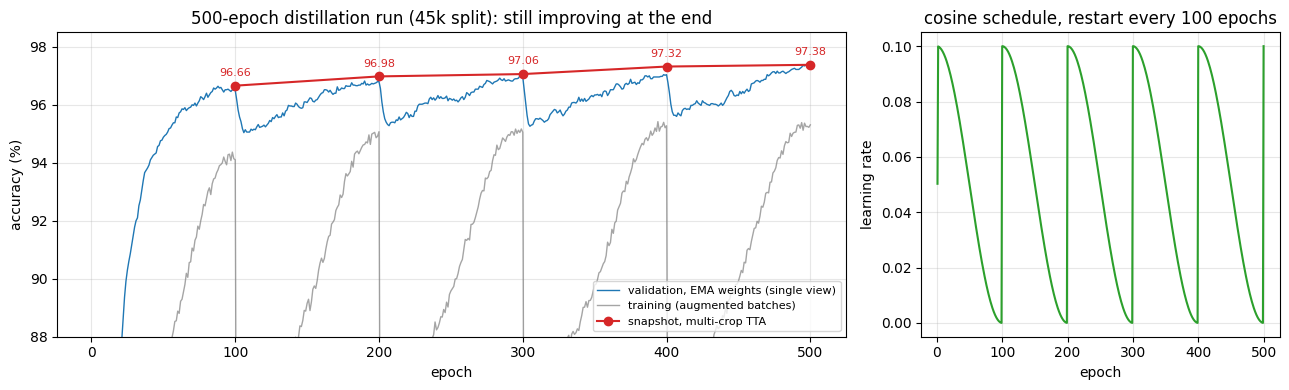

In [30]:
# ---- Phase 8 plot: validation accuracy over the 500-epoch run (reads saved files only, no GPU needed) ----
P8_RUN = 'p8_long500_val_r222_80'
hist8 = json.load(open(os.path.join(RUNS_DIR, P8_RUN, 'history.json')))['history']
snap8 = pd.read_csv(os.path.join(RUNS_DIR, P8_RUN, 'snapshots.csv'))
ep8 = [r['epoch'] for r in hist8]

fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={'width_ratios': [2.2, 1]})
ax[0].plot(ep8, [r['ema_val_acc'] for r in hist8], lw=1, color='tab:blue', label='validation, EMA weights (single view)')
ax[0].plot(ep8, [r['train_acc'] for r in hist8], lw=1, color='tab:gray', alpha=.7, label='training (augmented batches)')
ax[0].plot(snap8['epoch'], snap8['val_acc_mtta'], 'o-', color='tab:red', label='snapshot, multi-crop TTA')
for e, a in zip(snap8['epoch'], snap8['val_acc_mtta']):
    ax[0].annotate(f'{a:.2f}', (e, a), textcoords='offset points', xytext=(0, 7), ha='center', fontsize=8, color='tab:red')
ax[0].set(xlabel='epoch', ylabel='accuracy (%)', ylim=(88, 98.5),
          title='500-epoch distillation run (45k split): still improving at the end')
ax[0].grid(alpha=.3); ax[0].legend(fontsize=8, loc='lower right')
ax[1].plot(ep8, [r['lr'] for r in hist8], color='tab:green')
ax[1].set(xlabel='epoch', ylabel='learning rate', title='cosine schedule, restart every 100 epochs')
ax[1].grid(alpha=.3)
plt.tight_layout(); plt.show()

## Final model and results summary

The submitted model from this notebook is **`final_full_p5_r222_80`** (Phase 5, step 3):

- **Architecture:** `r222_80`, a 3×3 stem (80 channels), then 3 stages × 2 basic blocks at 80 / 160 / 320 channels (32×32 → 16×16 → 8×8), global average pooling, and a linear classifier.
- **Training:** SGD with Nesterov momentum, peak learning rate 0.1, 2-epoch warmup + cosine schedule, batch 256, weight decay 5e-4, label smoothing 0.1, EMA 0.999, AutoAugment + crop/flip + Cutout 16, 150 epochs on all 50k images. Distilled (α = 0.7, T = 4) from 2 × `r343_64` + WRN-28-10, which are used only during training.
- **Inference:** multi-crop TTA (10 views).

The next cell loads the saved model, **counts its trainable parameters, and prints its test accuracy**. Test labels are hidden, so the test accuracy is the score Kaggle reported; the validation estimate comes from the two runs of the same recipe on the 45k split.

In [31]:
# ---- Final model: number of parameters and test accuracy (needs the Setup cells; no training) ----
FINAL_RUN = 'final_full_p5_r222_80'                        # the submitted model (trained on all 50k images)
VAL_RUNS  = ['p5_kd_ens3_r222_80', 'p6_kd3_s1_r222_80']    # same recipe on the 45k split (seeds 0, 1)

final_model, final_cfg = load_run_model(FINAL_RUN)
n_params = count_params(final_model)
assert n_params <= PARAM_LIMIT, 'over the 5M budget'

res = pd.read_csv(RESULTS_CSV).drop_duplicates('name', keep='last').set_index('name')
val_accs = [float(res.loc[r, 'final_val_acc_mtta']) for r in VAL_RUNS]

# Test accuracy as reported by the Kaggle leaderboard (test labels are not public, so it can't be computed here)
KAGGLE_PUBLIC, KAGGLE_PRIVATE = 0.887, 0.857

arch = ARCH_PRESETS[final_cfg['arch']]
print(f"Final model            : {FINAL_RUN}  ({final_cfg['arch']}: widths {arch['widths']}, blocks per stage {arch['blocks']})")
print(f"Trainable parameters   : {n_params:,}  (limit {PARAM_LIMIT:,})")
print(f"Training               : {final_cfg['epochs']} epochs on all 50k images, KD from {final_cfg['teacher']} "
      f"(alpha={final_cfg['kd_alpha']}, T={final_cfg['kd_T']})")
print(f"Validation accuracy    : {val_accs[0]:.2f} / {val_accs[1]:.2f} %  (same recipe on the 45k split, multi-crop TTA, 2 seeds)")
print(f"TEST ACCURACY (Kaggle) : public {KAGGLE_PUBLIC:.3f} | private {KAGGLE_PRIVATE:.3f}")

Final model            : final_full_p5_r222_80  (r222_80: widths [80, 160, 320], blocks per stage [2, 2, 2])
Trainable parameters   : 4,337,370  (limit 5,000,000)
Training               : 150 epochs on all 50k images, KD from ['p3_long_s0', 'p3_long_s1', 'teacher_wrn28_10'] (alpha=0.7, T=4.0)
Validation accuracy    : 97.00 / 97.14 %  (same recipe on the 45k split, multi-crop TTA, 2 seeds)
TEST ACCURACY (Kaggle) : public 0.887 | private 0.857


**How validation accuracy grew through the phases.** Each bar is the best configuration of a phase, read from `results.csv`. Early phases are short runs reported without TTA; the 150- and 500-epoch runs use TTA, as labeled.

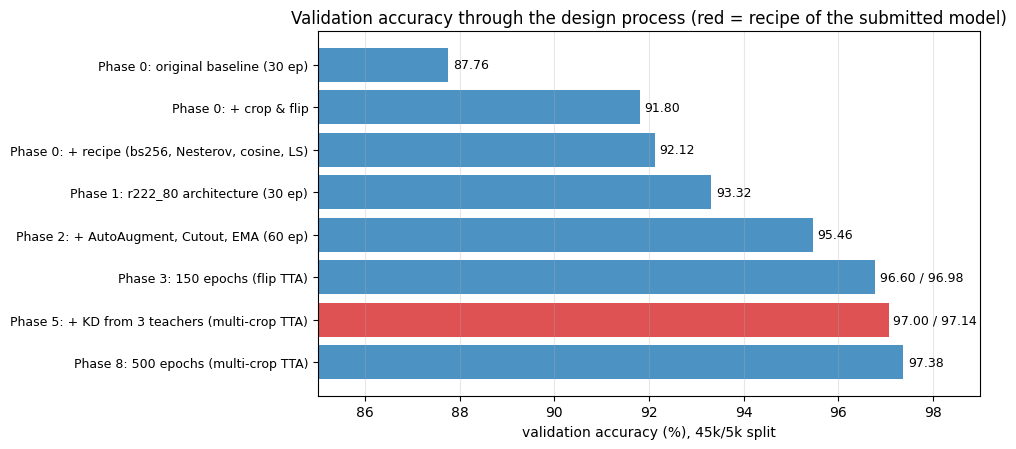

In [32]:
# ---- Summary plot: validation accuracy through the design process (reads results.csv only) ----
STEPS = [  # (label, run name(s), metric column)
    ('Phase 0: original baseline (30 ep)',            ['p0_A_original'],                          'val_acc'),
    ('Phase 0: + crop & flip',                         ['p0_B_aug'],                               'val_acc'),
    ('Phase 0: + recipe (bs256, Nesterov, cosine, LS)', ['p0_C_aug_recipe'],                       'val_acc'),
    ('Phase 1: r222_80 architecture (30 ep)',          ['p1_r222_80'],                             'val_acc'),
    ('Phase 2: + AutoAugment, Cutout, EMA (60 ep)',    ['p2_combo_r222_80'],                       'val_acc'),
    ('Phase 3: 150 epochs (flip TTA)',                 ['p3_long_s0_r222_80', 'p3_long_s1_r222_80'], 'val_acc_tta'),
    ('Phase 5: + KD from 3 teachers (multi-crop TTA)', ['p5_kd_ens3_r222_80', 'p6_kd3_s1_r222_80'],  'final_val_acc_mtta'),
    ('Phase 8: 500 epochs (multi-crop TTA)',           ['p8_long500_val_r222_80'],                 'final_val_acc_mtta'),
]
res = pd.read_csv(RESULTS_CSV).drop_duplicates('name', keep='last').set_index('name')
labels, means, seeds = [], [], []
for label, runs, col in STEPS:
    v = [float(res.loc[r, col]) for r in runs]
    labels.append(label); means.append(np.mean(v)); seeds.append(v)

fig, ax = plt.subplots(figsize=(10, 4.6))
y = np.arange(len(STEPS))[::-1]
colors = ['tab:red' if 'Phase 5' in l else 'tab:blue' for l in labels]
ax.barh(y, means, color=colors, alpha=.8)
for yi, m, v in zip(y, means, seeds):
    ax.text(m + 0.1, yi, ' / '.join(f'{a:.2f}' for a in v), va='center', fontsize=9)
ax.set_yticks(y); ax.set_yticklabels(labels, fontsize=9)
ax.set_xlim(85, 99); ax.set_xlabel('validation accuracy (%), 45k/5k split')
ax.set_title('Validation accuracy through the design process (red = recipe of the submitted model)')
ax.grid(axis='x', alpha=.3); plt.tight_layout(); plt.show()

### All results
Every finished run in `results.csv`, sorted by validation accuracy. Rows starting `final_` were trained on all 50k images and have no validation accuracy.

In [33]:
display(show_results())

,name,arch,params,epochs,val_acc,val_acc_tta,ema_val_acc,ema_val_acc_tta,final_val_acc_mtta,best_val_acc,train_acc,sec_per_epoch,notes
0,p8_long500_val_r222_80,r222_80,4337370,500,97.36,97.44,97.46,97.36,97.38,97.44,95.31,25.86,NaN
1,p6_kd3_cw15_s0_r222_80,r222_80,4337370,150,97.00,97.10,97.02,97.14,97.18,97.08,95.12,7.84,loss weight cat/dog x1.5
2,p6_kd5_s0_r222_80,r222_80,4337370,150,96.96,97.06,97.04,97.10,97.20,97.04,95.10,8.83,KD from 5-model ensemble
3,p6_kd3_s1_r222_80,r222_80,4337370,150,96.94,97.12,97.00,97.14,97.14,97.06,95.02,7.55,"KD ens3 baseline, seed 1"
4,p5_kd_ens3_r222_80,r222_80,4337370,150,96.88,97.10,96.86,97.06,97.00,97.00,94.95,7.85,KD from 2 seeds + WRN-28-10
5,p5_kd_ens2_r222_80,r222_80,4337370,150,96.88,97.40,96.94,97.46,97.34,97.00,95.22,7.96,KD from 2 student seeds
6,p6_kd3_os15_s1_r222_80,r222_80,4337370,150,96.84,97.06,96.86,97.14,97.06,96.86,95.02,7.55,oversample cat/dog x1.5
7,p3_long_s1,r343_64,4623178,150,96.82,97.28,96.78,97.26,NaN,96.84,95.14,18.48,NaN
8,p6_kd3_cw15_s1_r222_80,r222_80,4337370,150,96.80,97.04,96.76,97.06,97.02,96.92,95.02,7.79,loss weight cat/dog x1.5
9,p7_photo_deg_s0_r222_80,r222_80,4337370,150,96.78,97.00,96.72,96.94,97.00,96.84,93.30,9.03,KD5 + photometric + blur/sharpen
